In [ ]:
from capstone_data import load_dataset, chronological_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

btc = load_dataset("bitcoin")

train, validation, test = chronological_split(btc)

print("Dataset shape:", btc.shape)

print("\nFirst observations:")
display(btc.head())

print("\nLast observations:")
display(btc.tail())

print("\nMissing values:")
print(btc.isna().sum())

print("\nDataset metadata:")
print(btc.attrs.get("capstone"))

Dataset shape: (1827, 7)

Columns:
Index(['Close', 'High', 'Low', 'Open', 'Volume', 'log_return',
       'squared_log_return'],
      dtype='str')

First observations:


,Close,High,Low,Open,Volume,log_return,squared_log_return
time,,,,,,,
2020-01-01,7200.174316,7254.330566,7174.944336,7194.892090,18565664997,NaN,NaN
2020-01-02,6985.470215,7212.155273,6935.270020,7202.551270,20802083465,-0.030273,9.164502e-04
2020-01-03,7344.884277,7413.715332,6914.996094,6984.428711,28111481032,0.050172,2.517204e-03
2020-01-04,7410.656738,7427.385742,7309.514160,7345.375488,18444271275,0.008915,7.947740e-05
2020-01-05,7411.317383,7544.497070,7400.535645,7410.451660,19725074095,0.000089,7.946641e-09



Last observations:


,Close,High,Low,Open,Volume,log_return,squared_log_return
time,,,,,,,
2024-12-27,94164.859375,97294.843750,93310.742188,95704.976562,52419934565,-0.017169,0.000295
2024-12-28,95163.929688,95525.898438,94014.289062,94160.187500,24107436185,0.010554,0.000111
2024-12-29,93530.226562,95174.875000,92881.789062,95174.054688,29635885267,-0.017316,0.000300
2024-12-30,92643.210938,94903.320312,91317.132812,93527.195312,56188003691,-0.009529,0.000091
2024-12-31,93429.203125,96090.601562,91914.031250,92643.250000,43625106843,0.008448,0.000071



Missing values:
Close                 0
High                  0
Low                   0
Open                  0
Volume                0
log_return            1
squared_log_return    1
dtype: int64

Dataset metadata:
{'title': 'Bitcoin daily volatility', 'file': 'snapshots/bitcoin.csv.gz', 'sha256': '0269eecb9286ac12b306b439f31b03e14bc4d7e0696e3732c9d0cd741ba5093d', 'rows': 1827, 'columns': ['Close', 'High', 'Low', 'Open', 'Volume', 'log_return', 'squared_log_return'], 'start': '2020-01-01 00:00:00', 'end': '2024-12-31 00:00:00', 'index_kind': 'datetime', 'frequency': 'D', 'missing': {'Close': 0, 'High': 0, 'Low': 0, 'Open': 0, 'Volume': 0, 'log_return': 1, 'squared_log_return': 1}, 'target': 'squared_log_return', 'horizon': 7, 'units': 'squared log return (daily variance proxy; not intraday realized variance)', 'sources': ['bitcoin_yahoo.csv'], 'source_page': 'https://finance.yahoo.com/quote/BTC-USD/history/', 'preparation': 'Daily adjusted OHLC; explicit auto_adjust=True; natural-log

In [3]:
import requests
import pandas as pd

BASE_URL = "https://api.blockchain.info/charts"

charts = {
    "hash_rate": "hash-rate",
    "difficulty": "difficulty",
    "fees_btc": "transaction-fees"
}

def download_blockchain_chart(chart_name):

    url = f"{BASE_URL}/{chart_name}"

    params = {
        "start": "2019-12-01",
        "timespan": "1900days",
        "format": "json",
        "sampled": "false"
    }

    response = requests.get(
        url,
        params=params,
        timeout=40
    )

    response.raise_for_status()

    data = response.json()

    if data.get("status") != "ok":
        raise ValueError(f"Unexpected API response: {data}")

    if data.get("period") != "day":
        raise ValueError(
            f"Expected daily observations, got {data.get('period')}"
        )

    values = pd.DataFrame(data["values"])

    if values.empty:
        raise ValueError(f"No observations returned for {chart_name}")

    dates = (
        pd.to_datetime(values["x"], unit="s", utc=True)
        .dt.normalize()
        .dt.tz_localize(None)
    )

    series = pd.Series(
        pd.to_numeric(values["y"], errors="coerce").to_numpy(),
        index=pd.DatetimeIndex(dates),
        name=chart_name
    ).sort_index()

    if not series.index.is_unique:
        raise ValueError(f"Duplicate daily dates for {chart_name}")

    return series

onchain = pd.concat(
    {
        name: download_blockchain_chart(chart)
        for name, chart in charts.items()
    },
    axis=1
)

print(onchain.shape)

display(onchain.head())
display(onchain.tail())

print("\nMissing values:")
print(onchain.isna().sum())

(1901, 3)


,hash_rate,difficulty,fees_btc
x,,,
2019-12-01,8.964153e+07,1.297324e+13,21.908764
2019-12-02,9.351094e+07,1.297324e+13,26.091090
2019-12-03,1.018947e+08,1.297324e+13,25.477341
2019-12-04,1.076988e+08,1.297324e+13,29.545539
2019-12-05,9.338636e+07,1.295595e+13,23.241657


,hash_rate,difficulty,fees_btc
x,,,
2025-02-08,8.598320e+08,1.081054e+14,4.520147
2025-02-09,7.952938e+08,1.118782e+14,3.493630
2025-02-10,7.888647e+08,1.141673e+14,4.581370
2025-02-11,7.037354e+08,1.141673e+14,5.258301
2025-02-12,7.548130e+08,1.141673e+14,4.636798



Missing values:
hash_rate     0
difficulty    0
fees_btc      0
dtype: int64


In [4]:
onchain.to_csv(
    "btc_onchain_raw.csv",
    index_label="date"
)

onchain_cols = ["hash_rate", "difficulty", "fees_btc"]

btc_full = btc.join(
    onchain,
    how="left",
    validate="one_to_one"
)

# Lag on the full historical series, including December 2019.
onchain_lagged = onchain[onchain_cols].shift(7)

onchain_lagged = onchain_lagged.rename(
    columns={col: f"{col}_lag7" for col in onchain_cols}
)

# Align only after creating the lags.
btc_full = btc_full.join(
    onchain_lagged,
    how="left",
    validate="one_to_one"
)

lagged_cols = onchain_lagged.columns.tolist()

print(btc_full[lagged_cols].isna().sum())
display(btc_full.head())

hash_rate_lag7     0
difficulty_lag7    0
fees_btc_lag7      0
dtype: int64


,Close,High,Low,Open,Volume,log_return,squared_log_return,hash_rate,difficulty,fees_btc,hash_rate_lag7,difficulty_lag7,fees_btc_lag7
time,,,,,,,,,,,,,
2020-01-01,7200.174316,7254.330566,7174.944336,7194.892090,18565664997,NaN,NaN,1.127185e+08,1.303166e+13,9.971000,8.239079e+07,1.294859e+13,13.131968
2020-01-02,6985.470215,7212.155273,6935.270020,7202.551270,20802083465,-0.030273,9.164502e-04,9.671772e+07,1.379878e+13,13.780845,1.074942e+08,1.294859e+13,18.912097
2020-01-03,7344.884277,7413.715332,6914.996094,6984.428711,28111481032,0.050172,2.517204e-03,1.159241e+08,1.379878e+13,16.389795,9.333332e+07,1.294859e+13,17.116338
2020-01-04,7410.656738,7427.385742,7309.514160,7345.375488,18444271275,0.008915,7.947740e-05,1.152381e+08,1.379878e+13,12.312165,9.590803e+07,1.294859e+13,13.803910
2020-01-05,7411.317383,7544.497070,7400.535645,7410.451660,19725074095,0.000089,7.946641e-09,1.118084e+08,1.379878e+13,11.887112,9.977010e+07,1.294859e+13,12.609247


In [5]:
print("Combined dataset shape:", btc_full.shape)

display(btc_full.head())

print("\nMissing on-chain observations:")
print(
    btc_full[
        ["hash_rate", "difficulty", "fees_btc"]
    ].isna().sum()
)

Combined dataset shape: (1827, 13)


,Close,High,Low,Open,Volume,log_return,squared_log_return,hash_rate,difficulty,fees_btc,hash_rate_lag7,difficulty_lag7,fees_btc_lag7
time,,,,,,,,,,,,,
2020-01-01,7200.174316,7254.330566,7174.944336,7194.892090,18565664997,NaN,NaN,1.127185e+08,1.303166e+13,9.971000,8.239079e+07,1.294859e+13,13.131968
2020-01-02,6985.470215,7212.155273,6935.270020,7202.551270,20802083465,-0.030273,9.164502e-04,9.671772e+07,1.379878e+13,13.780845,1.074942e+08,1.294859e+13,18.912097
2020-01-03,7344.884277,7413.715332,6914.996094,6984.428711,28111481032,0.050172,2.517204e-03,1.159241e+08,1.379878e+13,16.389795,9.333332e+07,1.294859e+13,17.116338
2020-01-04,7410.656738,7427.385742,7309.514160,7345.375488,18444271275,0.008915,7.947740e-05,1.152381e+08,1.379878e+13,12.312165,9.590803e+07,1.294859e+13,13.803910
2020-01-05,7411.317383,7544.497070,7400.535645,7410.451660,19725074095,0.000089,7.946641e-09,1.118084e+08,1.379878e+13,11.887112,9.977010e+07,1.294859e+13,12.609247



Missing on-chain observations:
hash_rate     0
difficulty    0
fees_btc      0
dtype: int64


In [6]:
coverage = pd.DataFrame({
    "observations": btc_full[onchain_cols].notna().sum(),
    "missing": btc_full[onchain_cols].isna().sum(),
    "coverage_pct": (
        100 * btc_full[onchain_cols].notna().mean()
    )
})

display(coverage.round(2))

,observations,missing,coverage_pct
hash_rate,1827,0,100.0
difficulty,1827,0,100.0
fees_btc,1827,0,100.0


In [7]:
btc_full.to_csv(
    "btc_market_onchain_aligned.csv",
    index_label="date"
)

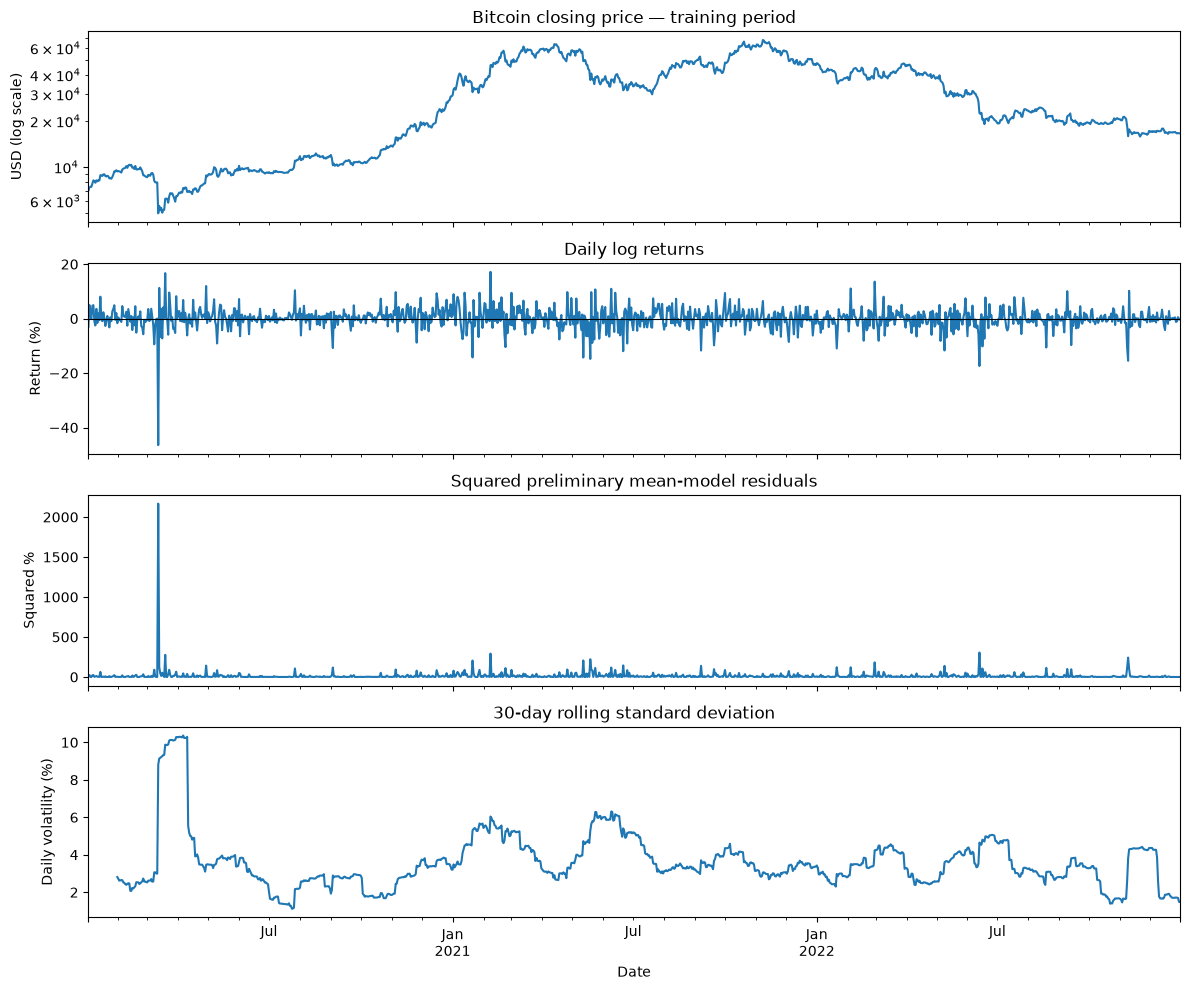

In [8]:

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.tsa.stattools import adfuller
from scipy.stats import jarque_bera

train, validation, test = chronological_split(btc_full)

# ARCH/GARCH convention: returns expressed in percent.
r_train = 100 * train["log_return"].dropna()

# Preliminary constant-mean model, as in Lecture 11.
mu_hat = r_train.mean()
resid = r_train - mu_hat

rolling_vol = r_train.rolling(30).std()

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

train["Close"].plot(ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Bitcoin closing price — training period")
axes[0].set_ylabel("USD (log scale)")

r_train.plot(ax=axes[1])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Daily log returns")
axes[1].set_ylabel("Return (%)")

(resid ** 2).plot(ax=axes[2])
axes[2].set_title("Squared preliminary mean-model residuals")
axes[2].set_ylabel("Squared %")

rolling_vol.plot(ax=axes[3])
axes[3].set_title("30-day rolling standard deviation")
axes[3].set_ylabel("Daily volatility (%)")
axes[3].set_xlabel("Date")

plt.tight_layout()
plt.show()


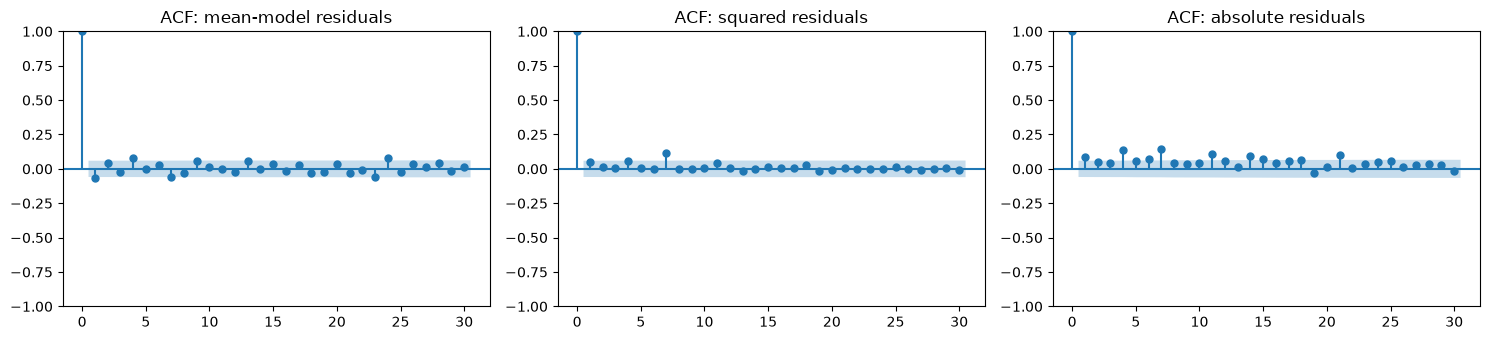

In [9]:

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))

plot_acf(
    resid,
    lags=30,
    ax=axes[0],
    title="ACF: mean-model residuals"
)

plot_acf(
    resid ** 2,
    lags=30,
    ax=axes[1],
    title="ACF: squared residuals"
)

plot_acf(
    resid.abs(),
    lags=30,
    ax=axes[2],
    title="ACF: absolute residuals"
)

plt.tight_layout()
plt.show()


In [10]:

# ADF: unit-root test for daily returns
adf_stat, adf_p, *_ = adfuller(r_train, autolag="AIC")

# Jarque-Bera: normality of preliminary mean-model residuals
jb_stat, jb_p = jarque_bera(resid)

summary = pd.DataFrame({
    "Test": ["ADF (returns)", "Jarque-Bera (residuals)"],
    "Statistic": [adf_stat, jb_stat],
    "p-value": [adf_p, jb_p]
})

display(summary)

# Ljung-Box: residual and squared-residual serial dependence
lb_resid = acorr_ljungbox(
    resid, lags=[5, 10, 20], return_df=True
)

lb_squared = acorr_ljungbox(
    resid ** 2, lags=[5, 10, 20], return_df=True
)

lb_results = pd.DataFrame({
    "Residual p-value": lb_resid["lb_pvalue"],
    "Squared-residual p-value": lb_squared["lb_pvalue"]
})

display(lb_results)

# ARCH-LM: lag sensitivity
arch_rows = []

for q in [1, 2, 5, 10]:
    lm, pvalue, _, _ = het_arch(
        resid,
        nlags=q,
        ddof=0
    )

    arch_rows.append({
        "Lags": q,
        "LM statistic": lm,
        "p-value": pvalue
    })

arch_results = pd.DataFrame(arch_rows)
display(arch_results)


,Test,Statistic,p-value
0,ADF (returns),-10.669771,4.196297e-19
1,Jarque-Bera (residuals),19549.718287,0.000000e+00


,Residual p-value,Squared-residual p-value
5,0.013137,0.258696
10,0.007563,0.023893
20,0.026212,0.243447


,Lags,LM statistic,p-value
0,1,2.594165,0.107258
1,2,2.663560,0.264007
2,5,6.319583,0.276352
3,10,20.473561,0.025079


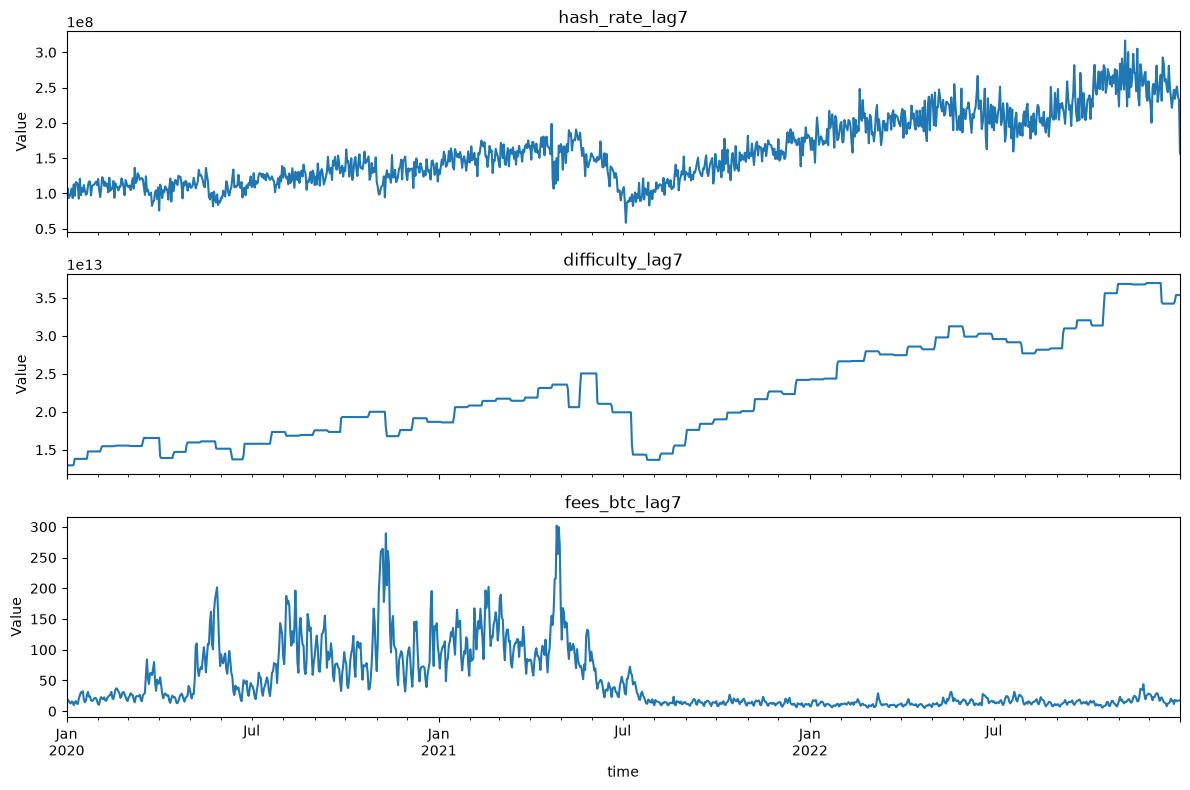

Training-period correlation matrix:


,hash_rate_lag7,difficulty_lag7,fees_btc_lag7
hash_rate_lag7,1.000,0.928,-0.344
difficulty_lag7,0.928,1.000,-0.297
fees_btc_lag7,-0.344,-0.297,1.000


In [11]:

onchain_features = [
    "hash_rate_lag7",
    "difficulty_lag7",
    "fees_btc_lag7"
]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

for ax, col in zip(axes, onchain_features):
    train[col].plot(ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

print("Training-period correlation matrix:")
display(train[onchain_features].corr().round(3))


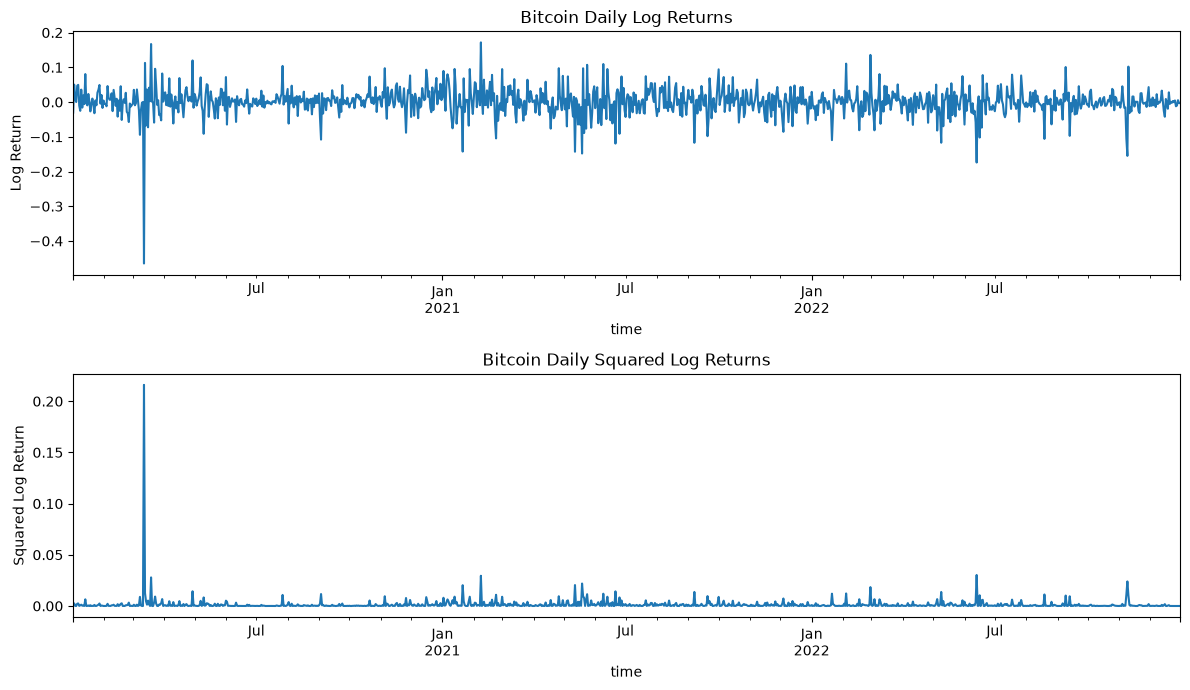

In [12]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

train, validation, test = chronological_split(btc_full)

r_train = train["log_return"].dropna()
v_train = train["squared_log_return"].dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

r_train.plot(ax=axes[0])
axes[0].set_title("Bitcoin Daily Log Returns")
axes[0].set_ylabel("Log Return")

v_train.plot(ax=axes[1])
axes[1].set_title("Bitcoin Daily Squared Log Returns")
axes[1].set_ylabel("Squared Log Return")

plt.tight_layout()
plt.show()

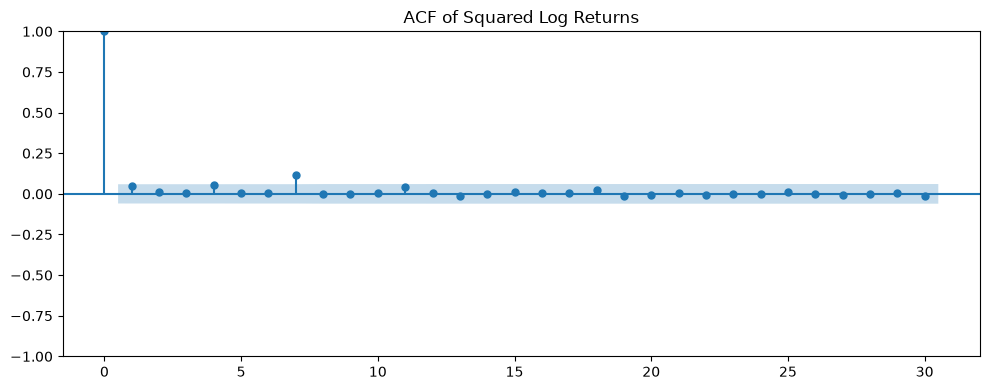

,lb_stat,lb_pvalue
5,6.467521,0.263346
10,20.922505,0.021640
20,24.375161,0.226388


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))

plot_acf(v_train, lags=30, ax=ax)

ax.set_title("ACF of Squared Log Returns")

plt.tight_layout()
plt.show()

lb_results = acorr_ljungbox(
    v_train,
    lags=[5, 10, 20],
    return_df=True
)

display(lb_results)

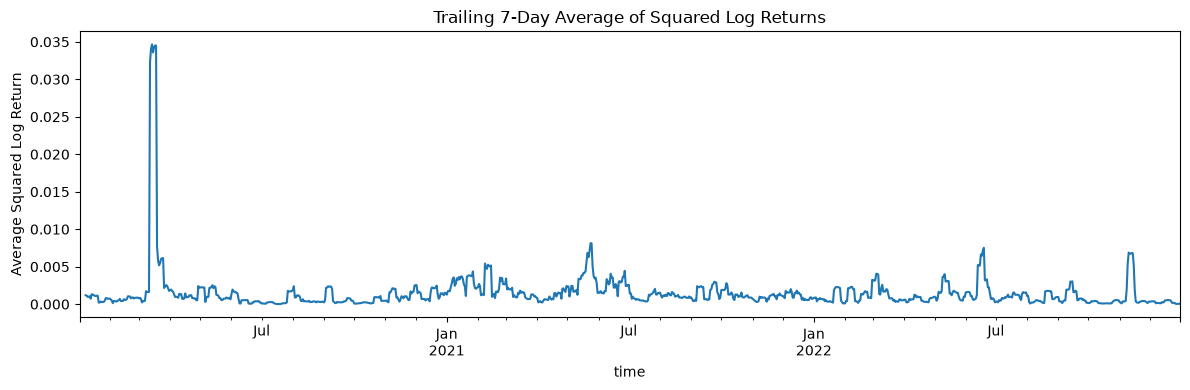

(1089,)


In [93]:
v7_train = v_train.rolling(7).mean()

fig, ax = plt.subplots(figsize=(12, 4))

v7_train.plot(ax=ax)

ax.set_title("Trailing 7-Day Average of Squared Log Returns")
ax.set_ylabel("Average Squared Log Return")

plt.tight_layout()
plt.show()
print(v7_train.dropna().shape)

In [15]:
train, validation, test = chronological_split(btc_full)

v_train = train["squared_log_return"]

# Target at time t: mean of squared returns at t+1, ..., t+7
y_train = (
    v_train.rolling(window=7, min_periods=7)
    .mean()
    .shift(-7)
    .dropna()
)

print(y_train.describe())
print(y_train.index.min(), y_train.index.max())

count    1089.000000
mean        0.001511
std         0.002900
min         0.000013
25%         0.000453
50%         0.000915
75%         0.001696
max         0.034666
Name: squared_log_return, dtype: float64
2020-01-01 00:00:00 2022-12-24 00:00:00


In [16]:
from scipy.stats import skew, kurtosis

y_plot = 10000 * y_train

# Descriptive statistics
summary = y_plot.describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
)

summary.loc["skewness"] = skew(y_plot)
summary.loc["excess kurtosis"] = kurtosis(y_plot)

display(summary.to_frame("7-day average squared return"))

,7-day average squared return
count,1089.000000
mean,15.113536
std,29.002726
min,0.132538
1%,0.521109
5%,1.239505
25%,4.528212
50%,9.149614
75%,16.956581
95%,38.263099


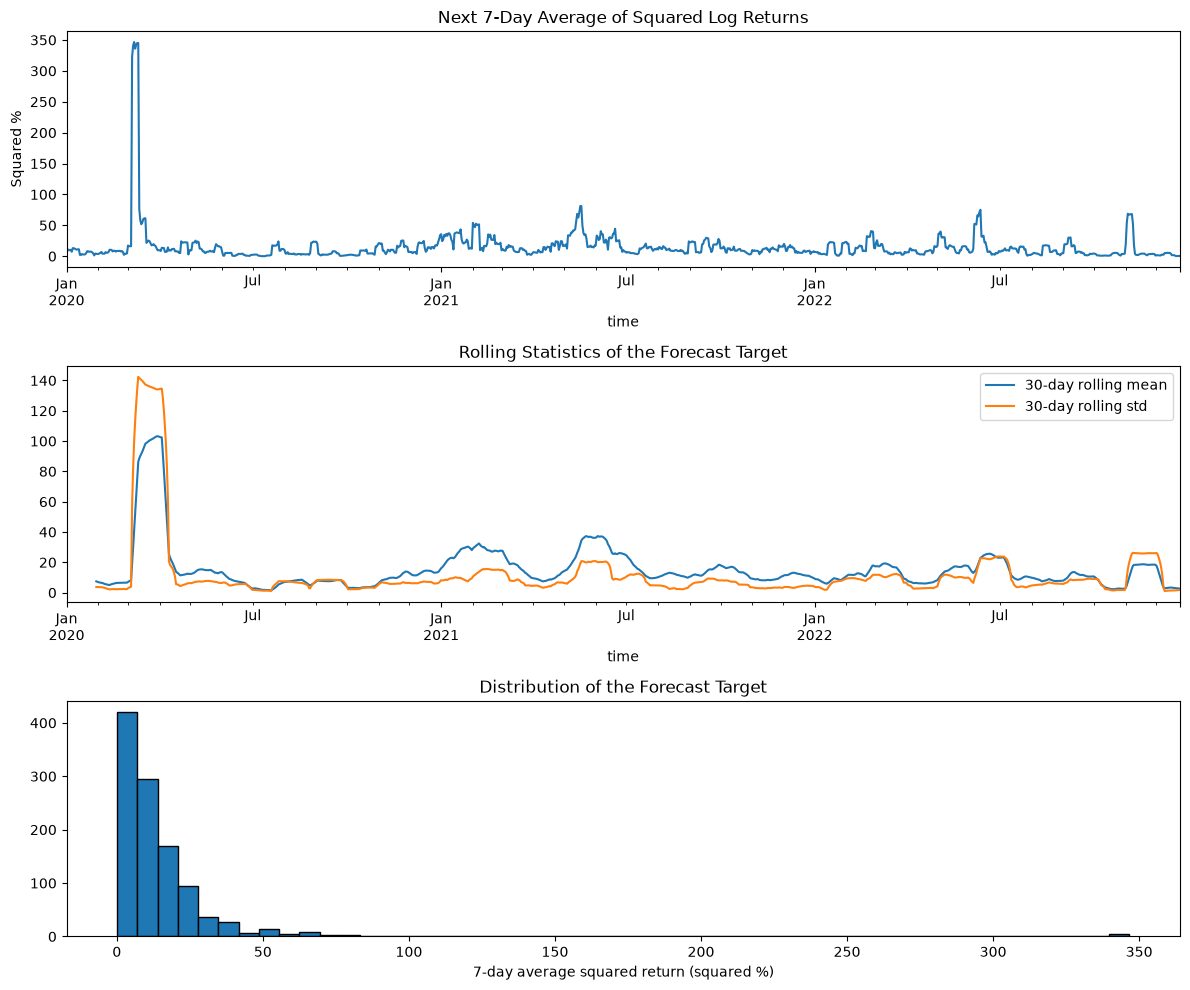

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

# Target series
y_plot.plot(ax=axes[0])
axes[0].set_title("Next 7-Day Average of Squared Log Returns")
axes[0].set_ylabel("Squared %")

# Rolling mean and standard deviation
y_plot.rolling(30).mean().plot(
    ax=axes[1], label="30-day rolling mean"
)

y_plot.rolling(30).std().plot(
    ax=axes[1], label="30-day rolling std"
)

axes[1].set_title("Rolling Statistics of the Forecast Target")
axes[1].legend()

# Distribution
axes[2].hist(y_plot, bins=50, edgecolor="black")
axes[2].set_title("Distribution of the Forecast Target")
axes[2].set_xlabel("7-day average squared return (squared %)")

plt.tight_layout()
plt.show()

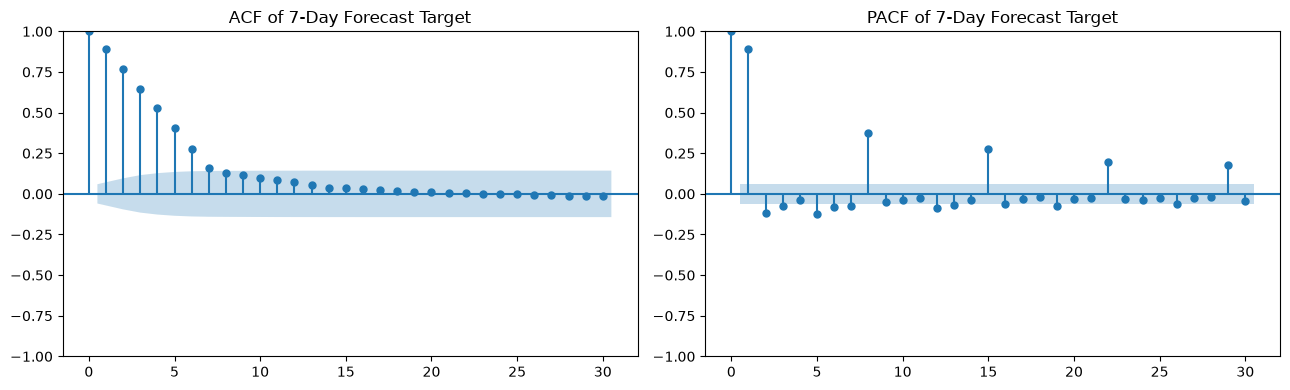

In [18]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

plot_acf(
    y_train,
    lags=30,
    ax=axes[0],
    title="ACF of 7-Day Forecast Target"
)

plot_pacf(
    y_train,
    lags=30,
    method="ywm",
    ax=axes[1],
    title="PACF of 7-Day Forecast Target"
)

plt.tight_layout()
plt.show()

In [19]:
from statsmodels.tsa.stattools import adfuller

adf = adfuller(y_train, autolag="AIC")

adf_results = pd.DataFrame({
    "Statistic": [adf[0]],
    "p-value": [adf[1]],
    "Lags used": [adf[2]],
    "Observations": [adf[3]]
}, index=["ADF"])

display(adf_results)

,Statistic,p-value,Lags used,Observations
ADF,-5.247437,0.000007,21,1067


In [20]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_target = acorr_ljungbox(
    y_train,
    lags=[7, 14, 21, 28],
    return_df=True
)

display(lb_target)

,lb_stat,lb_pvalue
7,2559.644379,0.0
14,2621.909306,0.0
21,2626.119697,0.0
28,2626.437013,0.0


In [21]:
lb_daily = acorr_ljungbox(
    v_train.dropna(),
    lags=[7, 14, 21, 28],
    return_df=True
)

display(lb_daily)

,lb_stat,lb_pvalue
7,20.831976,0.004027
14,23.038231,0.059650
21,24.426578,0.272852
28,24.712676,0.643425


In [22]:
from statsmodels.stats.diagnostic import het_arch
from scipy.stats import jarque_bera

# Percentage returns
r_train_pct = 100 * train["log_return"].dropna()

# Preliminary constant-mean specification
mu_hat = r_train_pct.mean()

resid = r_train_pct - mu_hat

# ARCH-LM tests for several lag choices
arch_results = []

for q in range(1,21):

    lm_stat, lm_p, _, _ = het_arch(
        resid,
        nlags=q
    )

    arch_results.append({
        "Lags": q,
        "LM statistic": lm_stat,
        "p-value": lm_p
    })

display(pd.DataFrame(arch_results))

# Normality diagnostic
jb_stat, jb_p = jarque_bera(resid)

print("Jarque-Bera statistic:", jb_stat)
print("Jarque-Bera p-value:", jb_p)

,Lags,LM statistic,p-value
0,1,2.594165,0.107258
1,2,2.663560,0.264007
2,3,2.675522,0.444403
3,4,6.321179,0.176412
4,5,6.319583,0.276352
5,6,6.312258,0.389135
6,7,20.074982,0.005410
7,8,20.412226,0.008884
8,9,20.417773,0.015502
9,10,20.473561,0.025079


Jarque-Bera statistic: 19549.71828653177
Jarque-Bera p-value: 0.0


In [23]:

from arch import arch_model
import pandas as pd
import numpy as np

r_train = 100 * train["log_return"].dropna()

candidates = {
    "ARCH(1)": {"vol": "ARCH", "p": 1},
    "ARCH(5)": {"vol": "ARCH", "p": 5},
    "GARCH(1,1)": {"vol": "GARCH", "p": 1, "q": 1},
    "GARCH(2,1)": {"vol": "GARCH", "p": 2, "q": 1}
}

fitted_models = {}
rows = []

for name, params in candidates.items():

    model = arch_model(
        r_train,
        mean="Constant",
        dist="normal",
        rescale=False,
        **params
    )

    result = model.fit(disp="off")

    fitted_models[name] = result

    rows.append({
        "Model": name,
        "Log-Likelihood": result.loglikelihood,
        "AIC": result.aic,
        "BIC": result.bic,
        "Convergence flag": result.convergence_flag
    })

comparison = pd.DataFrame(rows).set_index("Model")

display(comparison.sort_values("BIC"))


,Log-Likelihood,AIC,BIC,Convergence flag
Model,,,,
ARCH(5),-2982.027022,5978.054044,6013.043611,0
"GARCH(1,1)",-3010.560079,6029.120157,6049.114196,0
"GARCH(2,1)",-3008.300478,6026.600956,6051.593504,0
ARCH(1),-3034.967587,6075.935175,6090.930704,0


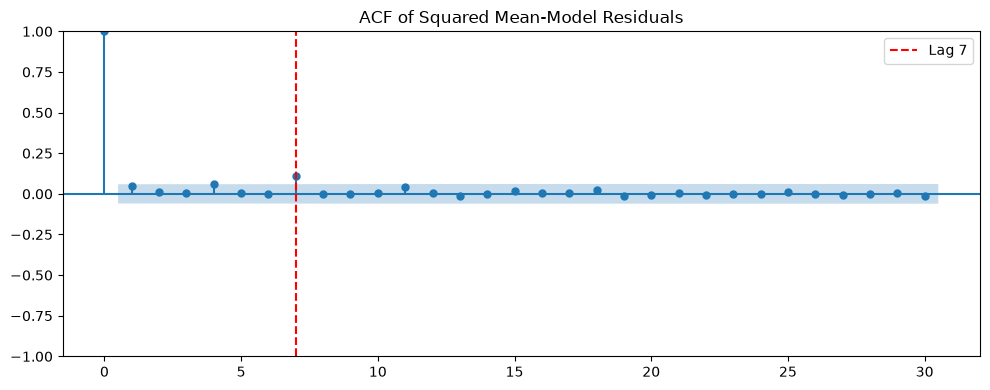

In [24]:
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(10, 4))

plot_acf(
    resid**2,
    lags=30,
    ax=ax
)

ax.axvline(
    7,
    color="red",
    linestyle="--",
    label="Lag 7"
)

ax.set_title("ACF of Squared Mean-Model Residuals")
ax.legend()

plt.tight_layout()
plt.show()

In [25]:
import statsmodels.api as sm

sq_resid = resid**2

aux_data = pd.DataFrame({"y": sq_resid})

for q in range(1, 8):
    aux_data[f"lag{q}"] = sq_resid.shift(q)

aux_data = aux_data.dropna()

X = sm.add_constant(aux_data.drop(columns="y"))
y = aux_data["y"]

aux_model = sm.OLS(y, X).fit()

display(aux_model.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.018
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     2.900
Date:                Sat, 07 Nov 2026   Prob (F-statistic):            0.00523
Time:                        20:03:47   Log-Likelihood:                -6180.0
No. Observations:                1088   AIC:                         1.238e+04
Df Residuals:                    1080   BIC:                         1.242e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.8217      2.431      4.862      0.000       7.051      16.593
lag1           0.0480      0.030      1.586      0.113      -0.011       0.107
lag2           0.0074      0.030      0.243      0.808      -0.052       0.067
lag3          -0.0060      0.030     -0.200      0.842      -0.065       0.053
lag4           0.0578      0.030      1.912      0.056      -0.002       0.117
lag5           0.0001      0.030      0.005      0.996      -0.059       0.060
lag6          -0.0046      0.030     -0.151      0.880      -0.064       0.055
lag7           0.1128      0.030      3.732      0.000       0.054       0.172
==============================================================================
Omnibus:                     2744.838   Durbin-Watson:                   1.996
Prob(Omnibus):                  0.000   Jarque-Bera (JB):         27202757.582
Skew:                          25.857   Prob(JB):                         0.00
Kurtosis:                     775.908   Cond. No.                         97.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [26]:
v_train = train["squared_log_return"].dropna()

rows = []

for year, series in v_train.groupby(v_train.index.year):

    rows.append({
        "Year": year,
        "Observations": len(series),
        "ACF lag 7": series.autocorr(lag=7)
    })

display(pd.DataFrame(rows))

,Year,Observations,ACF lag 7
0,2020,365,0.119326
1,2021,365,0.117754
2,2022,365,0.003785


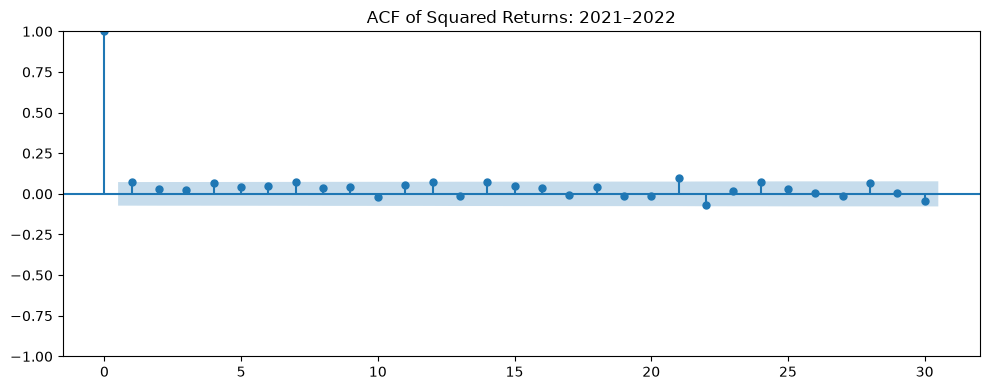

In [27]:
fig, ax = plt.subplots(figsize=(10, 4))

plot_acf(
    v_train.loc["2021":"2022"],
    lags=30,
    ax=ax
)

ax.set_title("ACF of Squared Returns: 2021–2022")

plt.tight_layout()
plt.show()

In [28]:

import numpy as np
import pandas as pd
from arch import arch_model

# Training data: 2020-2022
train, validation, test = chronological_split(btc_full)

# Use percentage log returns for numerical stability
r_train = 100 * train["log_return"].dropna()

# Candidate specifications
candidates = {
    "ARCH(1)":    {"vol": "ARCH",  "p": 1},
    "ARCH(5)":    {"vol": "ARCH",  "p": 5},
    "ARCH(7)":    {"vol": "ARCH",  "p": 7},
    "GARCH(1,1)": {"vol": "GARCH", "p": 1, "q": 1},
    "GARCH(2,1)": {"vol": "GARCH", "p": 2, "q": 1}
}

fitted_models = {}
results = []

for name, spec in candidates.items():

    model = arch_model(
        r_train,
        mean="Constant",
        dist="normal",
        hold_back=7,
        rescale=False,
        **spec
    )

    fit = model.fit(disp="off")
    fitted_models[name] = fit

    # Persistence: sum of ARCH and GARCH coefficients
    persistence = sum(
        value for param, value in fit.params.items()
        if param.startswith(("alpha[", "beta["))
    )

    results.append({
        "Model": name,
        "Log-Likelihood": fit.loglikelihood,
        "AIC": fit.aic,
        "BIC": fit.bic,
        "Persistence": persistence,
        "Convergence": fit.convergence_flag
    })

comparison = (
    pd.DataFrame(results)
    .set_index("Model")
    .sort_values("BIC")
)

display(comparison.round(4))


,Log-Likelihood,AIC,BIC,Persistence,Convergence
Model,,,,,
ARCH(7),-2951.7512,5921.5024,5966.4313,0.5139,0
ARCH(5),-2963.6911,5941.3821,5976.3268,0.4218,0
"GARCH(1,1)",-2991.9274,5991.8547,6011.8231,0.9361,0
"GARCH(2,1)",-2989.6473,5989.2945,6014.2550,0.9261,0
ARCH(1),-3016.3426,6038.6853,6053.6616,0.0345,0


In [29]:
coefficients = pd.DataFrame({
    name: fit.params
    for name, fit in fitted_models.items()
}).T

coefficients.index.name = "Model"

display(coefficients.round(5))

,alpha[1],alpha[2],alpha[3],alpha[4],alpha[5],alpha[6],alpha[7],beta[1],mu,omega
Model,,,,,,,,,,
ARCH(1),0.03447,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.06969,14.53424
ARCH(5),0.06730,0.00584,0.01679,0.29569,0.03619,NaN,NaN,NaN,0.19829,9.30853
ARCH(7),0.06513,0.00101,0.00932,0.28062,0.01915,0.07279,0.06588,NaN,0.15200,7.95235
"GARCH(1,1)",0.09185,NaN,NaN,NaN,NaN,NaN,NaN,0.84426,0.18670,1.13437
"GARCH(2,1)",0.04218,0.07439,NaN,NaN,NaN,NaN,NaN,0.80953,0.17985,1.34971


In [30]:
for name, fit in fitted_models.items():

    print(f"\n{name}")

    param_table = pd.DataFrame({
        "Coefficient": fit.params,
        "Std. Error": fit.std_err,
        "p-value": fit.pvalues
    })

    display(param_table.round(5))


ARCH(1)


,Coefficient,Std. Error,p-value
mu,0.06969,0.11989,0.56104
omega,14.53424,2.51505,0.00000
alpha[1],0.03447,0.03812,0.36586



ARCH(5)


,Coefficient,Std. Error,p-value
mu,0.19829,0.11161,0.07564
omega,9.30853,1.23458,0.00000
alpha[1],0.06730,0.04835,0.16390
alpha[2],0.00584,0.00804,0.46759
alpha[3],0.01679,0.02190,0.44329
alpha[4],0.29569,0.16321,0.07003
alpha[5],0.03619,0.03909,0.35455



ARCH(7)


,Coefficient,Std. Error,p-value
mu,0.15200,0.11531,0.18744
omega,7.95235,1.27083,0.00000
alpha[1],0.06513,0.04508,0.14852
alpha[2],0.00101,0.00706,0.88584
alpha[3],0.00932,0.01760,0.59668
alpha[4],0.28062,0.16185,0.08295
alpha[5],0.01915,0.02876,0.50556
alpha[6],0.07279,0.07917,0.35784
alpha[7],0.06588,0.04192,0.11605



GARCH(1,1)


,Coefficient,Std. Error,p-value
mu,0.18670,0.14047,0.18381
omega,1.13437,0.50104,0.02357
alpha[1],0.09185,0.06599,0.16395
beta[1],0.84426,0.04799,0.00000



GARCH(2,1)


,Coefficient,Std. Error,p-value
mu,0.17985,0.13159,0.17169
omega,1.34971,0.64900,0.03756
alpha[1],0.04218,0.04832,0.38269
alpha[2],0.07439,0.12531,0.55275
beta[1],0.80953,0.08676,0.00000


In [31]:

from arch import arch_model
from sklearn.metrics import mean_absolute_error, mean_squared_error

import numpy as np
import pandas as pd

H = 7

candidates = {
    "ARCH(1)": {"vol": "ARCH", "p": 1},
    "ARCH(5)": {"vol": "ARCH", "p": 5},
    "ARCH(7)": {"vol": "ARCH", "p": 7},
    "ARCH(8)": {"vol": "ARCH", "p": 8},
    "GARCH(1,1)": {"vol": "GARCH", "p": 1, "q": 1},
    "GARCH(2,1)": {"vol": "GARCH", "p": 2, "q": 1}
}

# Use the same estimation hold-back for every model.
hold_back = 8

# First forecast origin: December 31, 2022.
# 52 complete nonoverlapping target windows in 2023.
origins = pd.date_range(
    start=validation.index.min() - pd.Timedelta(days=1),
    periods=len(validation) // H,
    freq="7D"
)

records = []

for origin in origins:

    # All observed returns through this forecast origin.
    history = (
        100 * btc_full.loc[:origin, "log_return"].dropna()
    )

    # The actual next 7 days, used only for evaluation.
    future = btc_full.loc[
        origin + pd.Timedelta(days=1):
        origin + pd.Timedelta(days=H),
        "squared_log_return"
    ]

    # Previous 7 days for the naive benchmark.
    past = btc_full.loc[
        origin - pd.Timedelta(days=H-1):
        origin,
        "squared_log_return"
    ]

    assert len(future) == H and future.notna().all()
    assert len(past) == H and past.notna().all()
    assert future.index.min() >= validation.index.min()
    assert future.index.max() <= validation.index.max()

    row = {
        "origin": origin,
        "target_end": future.index[-1],
        "actual": future.mean(),
        "Naive": past.mean()
    }

    for name, spec in candidates.items():

        model = arch_model(
            history,
            mean="Constant",
            dist="normal",
            hold_back=hold_back,
            rescale=False,
            **spec
        )

        fit = model.fit(disp="off")

        if fit.convergence_flag != 0:
            raise RuntimeError(
                f"{name} failed to converge at {origin}"
            )

        fc = fit.forecast(
            horizon=H,
            method="analytic",
            reindex=False
        )

        # Predictive means and variances in percentage units.
        mean_fc = fc.mean.iloc[-1].to_numpy()
        var_fc = fc.variance.iloc[-1].to_numpy()

        # E[r^2] = Var(r) + E[r]^2.
        # Divide by 10,000 to return to log-return scale.
        squared_fc = (var_fc + mean_fc**2) / 10000

        if not np.isfinite(squared_fc).all():
            raise ValueError(
                f"Nonfinite forecast: {name}, {origin}"
            )

        row[name] = squared_fc.mean()

    records.append(row)

validation_forecasts = (
    pd.DataFrame(records)
    .set_index("origin")
)

display(validation_forecasts.head())


,target_end,actual,Naive,ARCH(1),ARCH(5),ARCH(7),ARCH(8),"GARCH(1,1)","GARCH(2,1)"
origin,,,,,,,,,
2022-12-31,2023-01-07,0.000029,0.000044,0.001499,0.001162,0.000990,0.000927,0.000967,0.000933
2023-01-07,2023-01-14,0.001322,0.000029,0.001489,0.001139,0.000956,0.000890,0.000876,0.000850
2023-01-14,2023-01-21,0.000912,0.001322,0.001503,0.001732,0.001671,0.001642,0.001462,0.001538
2023-01-21,2023-01-28,0.000104,0.000912,0.001485,0.001546,0.001448,0.001461,0.001447,0.001516
2023-01-28,2023-02-04,0.000507,0.000104,0.001476,0.001156,0.000985,0.000925,0.001055,0.001024


In [32]:

rows = []

model_names = ["Naive"] + list(candidates)

for name in model_names:

    actual = validation_forecasts["actual"]
    predicted = validation_forecasts[name]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    rows.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAE (x1e4)": mae * 10000,
        "RMSE (x1e4)": rmse * 10000
    })

validation_scores = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values("RMSE")
)

display(validation_scores.round(6))


,MAE,RMSE,MAE (x1e4),RMSE (x1e4)
Model,,,,
"GARCH(1,1)",0.000645,0.000746,6.446823,7.458555
"GARCH(2,1)",0.000651,0.000754,6.506509,7.542421
Naive,0.000530,0.000755,5.296405,7.550006
ARCH(8),0.000678,0.000787,6.778306,7.867284
ARCH(7),0.000695,0.000801,6.945267,8.008262
ARCH(5),0.000766,0.000862,7.655748,8.624212
ARCH(1),0.000936,0.001011,9.364105,10.112730


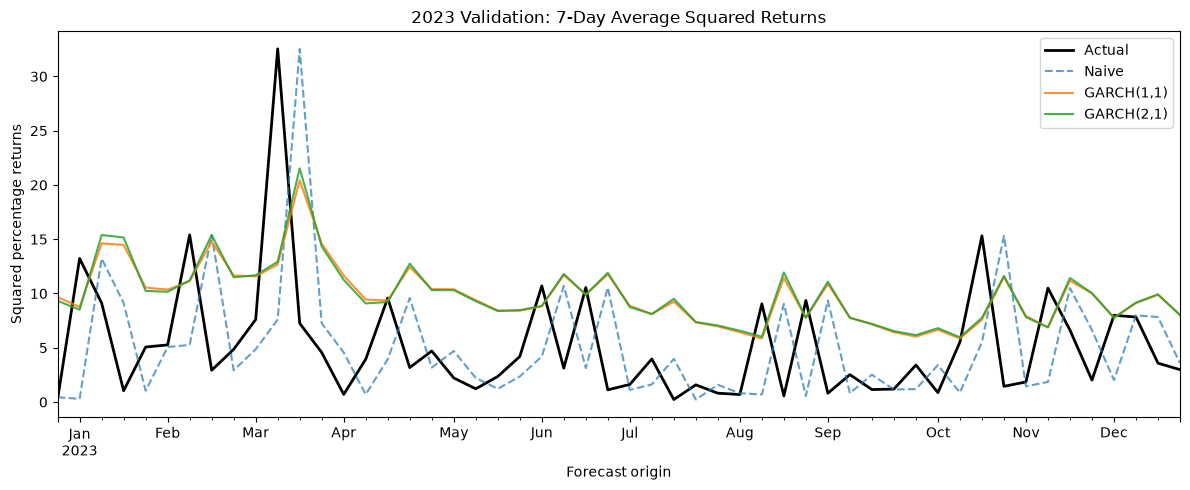

In [33]:

import matplotlib.pyplot as plt

best_two = (
    validation_scores
    .drop(index="Naive")
    .nsmallest(2, "RMSE")
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(12, 5))

scale = 10000

(validation_forecasts["actual"] * scale).plot(
    ax=ax,
    label="Actual",
    color="black",
    linewidth=2
)

(validation_forecasts["Naive"] * scale).plot(
    ax=ax,
    label="Naive",
    linestyle="--",
    alpha=0.7
)

for name in best_two:

    (validation_forecasts[name] * scale).plot(
        ax=ax,
        label=name,
        alpha=0.85
    )

ax.set_title("2023 Validation: 7-Day Average Squared Returns")
ax.set_ylabel("Squared percentage returns")
ax.set_xlabel("Forecast origin")
ax.legend()

plt.tight_layout()
plt.show()


In [34]:

import numpy as np
import pandas as pd
import statsmodels.api as sm

def dm_hac(forecasts, model_a, model_b,
           loss="squared", hac_lags=3):

    data = forecasts[
        ["actual", model_a, model_b]
    ].dropna().sort_index()

    # Rescale for numerical stability
    y = 1e4 * data["actual"].to_numpy()
    f_a = 1e4 * data[model_a].to_numpy()
    f_b = 1e4 * data[model_b].to_numpy()

    e_a = y - f_a
    e_b = y - f_b

    if loss == "squared":
        d = e_a**2 - e_b**2
    elif loss == "absolute":
        d = np.abs(e_a) - np.abs(e_b)
    else:
        raise ValueError("Unknown loss function")

    # Regression of loss differential on a constant
    X = np.ones((len(d), 1))

    result = sm.OLS(d, X).fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": hac_lags,
            "use_correction": True
        },
        use_t=True
    )

    return pd.Series({
        "N": len(d),
        "Mean loss difference": result.params[0],
        "Standard error": result.bse[0],
        "DM-HAC statistic": result.tvalues[0],
        "p-value": result.pvalues[0]
    })


In [35]:
dm_result = dm_hac(
    validation_forecasts,
    model_a="GARCH(1,1)",
    model_b="Naive",
    loss="squared",
    hac_lags=3
)

display(dm_result.to_frame("Result"))

,Result
N,52.000000
Mean loss difference,-1.372552
Standard error,12.161852
DM-HAC statistic,-0.112857
p-value,0.910587


In [36]:
dm_absolute = dm_hac(
    validation_forecasts,
    model_a="GARCH(1,1)",
    model_b="Naive",
    loss="absolute",
    hac_lags=3
)

display(dm_absolute.to_frame("Result"))

,Result
N,52.000000
Mean loss difference,1.150418
Standard error,0.603930
DM-HAC statistic,1.904887
p-value,0.062441


In [37]:
sensitivity = pd.DataFrame({
    lag: dm_hac(
        validation_forecasts,
        "GARCH(1,1)",
        "Naive",
        loss="squared",
        hac_lags=lag
    )
    for lag in [0, 1, 3, 5]
}).T

sensitivity.index.name = "HAC lags"

display(sensitivity.round(4))

,N,Mean loss difference,Standard error,DM-HAC statistic,p-value
HAC lags,,,,,
0,52.0,-1.3726,12.3685,-0.1110,0.9121
1,52.0,-1.3726,13.2540,-0.1036,0.9179
3,52.0,-1.3726,12.1619,-0.1129,0.9106
5,52.0,-1.3726,12.1084,-0.1134,0.9102


In [38]:
import numpy as np
import pandas as pd

from arch import arch_model
from sklearn.metrics import mean_absolute_error, mean_squared_error

train, validation, test = chronological_split(btc_full)

H = 7

# Forecast origins: December 31, 2023, then every seven days.
origins = pd.date_range(
    start=test.index.min() - pd.Timedelta(days=1),
    periods=len(test) // H,
    freq="7D"
)

records = []

for origin in origins:

    # Historical returns available at the forecast origin.
    history = (
        100 * btc_full.loc[:origin, "log_return"].dropna()
    )

    # Actual future target: next seven days.
    future = btc_full.loc[
        origin + pd.Timedelta(days=1):
        origin + pd.Timedelta(days=H),
        "squared_log_return"
    ]

    # Naive benchmark: previous seven days.
    past = btc_full.loc[
        origin - pd.Timedelta(days=H-1):
        origin,
        "squared_log_return"
    ]

    # Validate the forecast windows.
    assert len(future) == H and future.notna().all()
    assert len(past) == H and past.notna().all()

    assert future.index.min() >= test.index.min()
    assert future.index.max() <= test.index.max()

    # Fit the frozen GARCH(1,1) specification.
    model = arch_model(
        history,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        hold_back=8,
        rescale=False
    )

    fit = model.fit(disp="off")

    if fit.convergence_flag != 0:
        raise RuntimeError(
            f"GARCH failed to converge at {origin}"
        )

    # Seven-day analytical forecast.
    fc = fit.forecast(
        horizon=H,
        method="analytic",
        reindex=False
    )

    mean_fc = fc.mean.iloc[-1].to_numpy()
    var_fc = fc.variance.iloc[-1].to_numpy()

    # Convert conditional moments to squared log returns.
    squared_fc = (var_fc + mean_fc**2) / 10000

    if not np.isfinite(squared_fc).all():
        raise ValueError(f"Invalid forecast at {origin}")

    records.append({
        "origin": origin,
        "target_end": future.index[-1],
        "actual": future.mean(),
        "Naive": past.mean(),
        "GARCH(1,1)": squared_fc.mean()
    })

test_forecasts = (
    pd.DataFrame(records)
    .set_index("origin")
)

display(test_forecasts.head())

,target_end,actual,Naive,"GARCH(1,1)"
origin,,,,
2023-12-31,2024-01-07,0.000788,0.000260,0.000711
2024-01-07,2024-01-14,0.001675,0.000788,0.000872
2024-01-14,2024-01-21,0.000276,0.001675,0.001447
2024-01-21,2024-01-28,0.000690,0.000276,0.000952
2024-01-28,2024-02-04,0.000178,0.000690,0.000938


In [39]:
rows = []

for name in ["Naive", "GARCH(1,1)"]:

    actual = test_forecasts["actual"]
    predicted = test_forecasts[name]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    rows.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAE (x1e4)": mae * 10000,
        "RMSE (x1e4)": rmse * 10000
    })

test_scores = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values("RMSE")
)

display(test_scores.round(6))

,MAE,RMSE,MAE (x1e4),RMSE (x1e4)
Model,,,,
"GARCH(1,1)",0.000551,0.00071,5.508137,7.101402
Naive,0.000591,0.00086,5.905032,8.596143


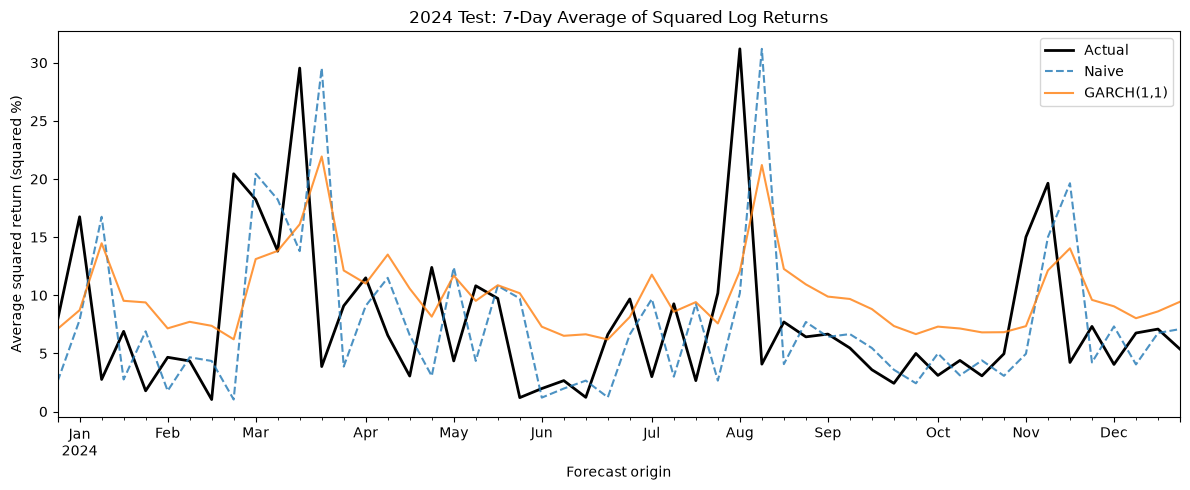

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))

scale = 10000

(test_forecasts["actual"] * scale).plot(
    ax=ax,
    label="Actual",
    color="black",
    linewidth=2
)

(test_forecasts["Naive"] * scale).plot(
    ax=ax,
    label="Naive",
    linestyle="--",
    alpha=0.8
)

(test_forecasts["GARCH(1,1)"] * scale).plot(
    ax=ax,
    label="GARCH(1,1)",
    alpha=0.8
)

ax.set_title(
    "2024 Test: 7-Day Average of Squared Log Returns"
)

ax.set_ylabel("Average squared return (squared %)")
ax.set_xlabel("Forecast origin")
ax.legend()

plt.tight_layout()
plt.show()

In [41]:
dm_test = dm_hac(
    test_forecasts,
    model_a="GARCH(1,1)",
    model_b="Naive",
    loss="squared",
    hac_lags=3
)

display(dm_test.to_frame("Test Result"))

,Test Result
N,52.000000
Mean loss difference,-23.463761
Standard error,11.997941
DM-HAC statistic,-1.955649
p-value,0.055996


In [42]:
import numpy as np
import pandas as pd
from arch import arch_model

H = 7
B = 10000

rng = np.random.default_rng(546)

intervals = []

for origin in test_forecasts.index:

    # Historical information available at the forecast origin
    history = (
        100 * btc_full.loc[:origin, "log_return"].dropna()
    )

    # Frozen GARCH(1,1) specification
    model = arch_model(
        history,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        hold_back=8,
        rescale=False
    )

    fit = model.fit(disp="off")

    if fit.convergence_flag != 0:
        raise RuntimeError(
            f"GARCH did not converge at {origin}"
        )

    # Simulate B possible paths over the next H days
    fc = fit.forecast(
        horizon=H,
        method="simulation",
        simulations=B,
        rng=rng.standard_normal,
        reindex=False
    )

    # Simulated future returns in percentage units
    simulated_returns = fc.simulations.values[-1]

    assert simulated_returns.shape == (B, H)

    # Compute our target for each simulated path
    simulated_targets = (
        np.mean(simulated_returns**2, axis=1) / 10000
    )

    # Equal-tailed 95% prediction interval
    lower, upper = np.quantile(
        simulated_targets,
        [0.025, 0.975]
    )

    intervals.append({
        "origin": origin,
        "lower_95": lower,
        "upper_95": upper
    })

intervals = pd.DataFrame(intervals).set_index("origin")

test_forecasts_ci = test_forecasts.join(intervals)

display(test_forecasts_ci.head())

,target_end,actual,Naive,"GARCH(1,1)",lower_95,upper_95
origin,,,,,,
2023-12-31,2024-01-07,0.000788,0.000260,0.000711,0.000127,0.002097
2024-01-07,2024-01-14,0.001675,0.000788,0.000872,0.000164,0.002442
2024-01-14,2024-01-21,0.000276,0.001675,0.001447,0.000266,0.004313
2024-01-21,2024-01-28,0.000690,0.000276,0.000952,0.000178,0.002705
2024-01-28,2024-02-04,0.000178,0.000690,0.000938,0.000183,0.002703


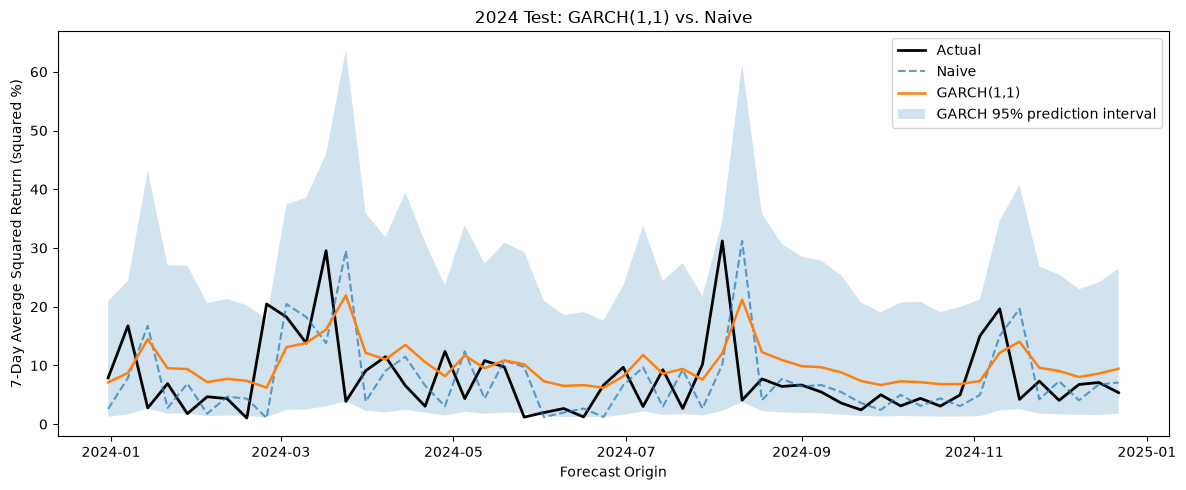

In [43]:
import matplotlib.pyplot as plt

scale = 10000

fig, ax = plt.subplots(figsize=(12, 5))

# Observed 7-day average squared returns
ax.plot(
    test_forecasts_ci.index,
    scale * test_forecasts_ci["actual"],
    label="Actual",
    color="black",
    linewidth=2
)

# Naive benchmark
ax.plot(
    test_forecasts_ci.index,
    scale * test_forecasts_ci["Naive"],
    label="Naive",
    linestyle="--",
    alpha=0.7
)

# GARCH(1,1) point forecast
ax.plot(
    test_forecasts_ci.index,
    scale * test_forecasts_ci["GARCH(1,1)"],
    label="GARCH(1,1)",
    linewidth=1.8
)

# Simulation-based 95% prediction interval
ax.fill_between(
    test_forecasts_ci.index,
    scale * test_forecasts_ci["lower_95"],
    scale * test_forecasts_ci["upper_95"],
    alpha=0.2,
    label="GARCH 95% prediction interval"
)

ax.set_title(
    "2024 Test: GARCH(1,1) vs. Naive"
)

ax.set_ylabel("7-Day Average Squared Return (squared %)")
ax.set_xlabel("Forecast Origin")

ax.legend()

plt.tight_layout()
plt.show()

In [44]:
actual = test_forecasts_ci["actual"]

lower = test_forecasts_ci["lower_95"]
upper = test_forecasts_ci["upper_95"]

inside = (actual >= lower) & (actual <= upper)

coverage = inside.mean()

below = (actual < lower).sum()
above = (actual > upper).sum()

average_width = (upper - lower).mean()

interval_results = pd.DataFrame({
    "Metric": [
        "Nominal coverage",
        "Empirical coverage",
        "Observations inside",
        "Observations below",
        "Observations above",
        "Average interval width (x1e4)"
    ],
    "Value": [
        0.95,
        coverage,
        inside.sum(),
        below,
        above,
        10000 * average_width
    ]
})

display(interval_results)

,Metric,Value
0,Nominal coverage,0.950000
1,Empirical coverage,0.884615
2,Observations inside,46.000000
3,Observations below,5.000000
4,Observations above,1.000000
5,Average interval width (x1e4),26.729853


In [85]:
btc_ml = btc_full.copy()

r = btc_ml["log_return"]
v = btc_ml["squared_log_return"]

ml_data = pd.DataFrame(index=btc_ml.index)

# Market features
ml_data["r_t"] = r
ml_data["abs_r_t"] = r.abs()
ml_data["v_t"] = v

ml_data["rv_7"] = v.rolling(7).mean()
ml_data["rv_14"] = v.rolling(14).mean()
ml_data["rv_30"] = v.rolling(30).mean()

ml_data["return_7"] = r.rolling(7).sum()

ml_data["range_t"] = np.log(
    btc_ml["High"] / btc_ml["Low"]
)

ml_data["log_volume"] = np.log1p(btc_ml["Volume"])

ml_data["volume_change_7"] = (
    ml_data["log_volume"]
    - ml_data["log_volume"].rolling(7).mean()
)

# On-chain features
onchain_features = [
    "hash_rate_lag7",
    "difficulty_lag7",
    "fees_btc_lag7"
]

ml_data[onchain_features] = btc_ml[onchain_features]

# Direct seven-day forward target
H = 7

ml_data["target_7"] = (
    sum(v.shift(-h) for h in range(1, H + 1)) / H
)

market_features = [
    "r_t",
    "abs_r_t",
    "v_t",
    "rv_7",
    "rv_14",
    "rv_30",
    "return_7",
    "range_t",
    "log_volume",
    "volume_change_7"
]

# Remove rows with incomplete predictors or targets
ml_data = ml_data.dropna(
    subset=market_features + onchain_features + ["target_7"]
)

display(ml_data.head())

,r_t,abs_r_t,v_t,rv_7,rv_14,rv_30,return_7,range_t,log_volume,volume_change_7,hash_rate_lag7,difficulty_lag7,fees_btc_lag7,target_7
time,,,,,,,,,,,,,,
2020-01-31,-0.016805,0.016805,0.000282,0.000747,0.000514,0.000840,0.101807,0.031031,24.105365,0.060184,1.116497e+08,1.477637e+13,16.100824,0.000362
2020-02-01,0.004518,0.004518,0.000020,0.000738,0.000515,0.000810,0.115555,0.013447,23.978383,-0.106394,1.204641e+08,1.477637e+13,11.393263,0.000366
2020-02-02,-0.005178,0.005178,0.000027,0.000637,0.000466,0.000727,0.083380,0.026863,24.151940,0.020078,1.050388e+08,1.477637e+13,10.572991,0.000453
2020-02-03,-0.005456,0.005456,0.000030,0.000459,0.000465,0.000725,0.042164,0.031057,24.155125,0.012292,9.475530e+07,1.477637e+13,19.787175,0.000546
2020-02-04,-0.012185,0.012185,0.000148,0.000135,0.000469,0.000730,-0.019163,0.023689,24.120896,-0.001881,1.073215e+08,1.520381e+13,22.987378,0.000700


In [86]:
origin = pd.Timestamp("2022-12-31")

# The seven dates AFTER the forecast origin
future_dates = pd.date_range(
    start=origin + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

# Retrieve the original squared returns
future_squared = btc_full.loc[
    future_dates, "squared_log_return"
]

# Calculate the target directly
manual_target = future_squared.sum() / 7

# Compare with our constructed target
constructed_target = ml_data.loc[origin, "target_7"]

display(future_squared.to_frame())

print("Manual target:     ", manual_target)
print("Constructed target:", constructed_target)

assert np.isclose(manual_target, constructed_target)

print("Verification passed!")

,squared_log_return
2023-01-01,2.188000e-05
2023-01-02,1.448336e-05
2023-01-03,2.665191e-07
2023-01-04,1.195557e-04
2023-01-05,2.473756e-06
2023-01-06,4.652321e-05
2023-01-07,3.363770e-08


Manual target:      2.931660006974289e-05
Constructed target: 2.931660006974289e-05
Verification passed!


In [87]:
actual_validation = validation_forecasts.loc[
    origin, "actual"
]

print("Manual target:     ", manual_target)
print("Validation actual: ", actual_validation)

assert np.isclose(manual_target, actual_validation)

Manual target:      2.931660006974289e-05
Validation actual:  2.931660006974289e-05


In [88]:
import numpy as np

all_origins = validation_forecasts.index.union(
    test_forecasts.index
)

for origin in all_origins:

    dates = pd.date_range(
        start=origin + pd.Timedelta(days=1),
        periods=7,
        freq="D"
    )

    manual = btc_full.loc[
        dates, "squared_log_return"
    ].sum() / 7

    constructed = ml_data.loc[origin, "target_7"]

    assert np.isclose(manual, constructed), (
        f"Target mismatch at {origin}"
    )

print(f"Verified {len(all_origins)} forecast targets.")

Verified 104 forecast targets.


In [46]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=10,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

In [47]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=250,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

In [48]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

models = {
    "RF": rf,
    "XGBoost": xgb
}

feature_sets = {
    "Market": market_features,
    "Market + On-chain": market_features + onchain_features
}

# Reuse the 52 forecast origins from GARCH validation
origins = validation_forecasts.index

ml_results = []

for origin in origins:

    # Only train on examples whose seven-day targets
    # are completely observed by this origin.
    cutoff = origin - pd.Timedelta(days=H)

    train_rows = ml_data.loc[ml_data.index <= cutoff]

    # Features known at the current forecast origin
    x_origin = ml_data.loc[[origin]]

    row = {
        "origin": origin
    }

    for model_name, estimator in models.items():

        for feature_name, features in feature_sets.items():

            fitted = clone(estimator)

            X_train = train_rows[features]

            # Scale target for easier numerical optimization
            y_train = 10000 * train_rows["target_7"]

            fitted.fit(X_train, y_train)

            prediction = fitted.predict(
                x_origin[features]
            )[0]

            # A squared-return forecast must be nonnegative
            prediction = max(0.0, prediction)

            row[f"{model_name} - {feature_name}"] = (
                prediction / 10000
            )

    ml_results.append(row)

ml_validation = (
    pd.DataFrame(ml_results)
    .set_index("origin")
)

display(ml_validation.head())

,RF - Market,RF - Market + On-chain,XGBoost - Market,XGBoost - Market + On-chain
origin,,,,
2022-12-31,0.000620,0.000586,0.000401,0.001139
2023-01-07,0.000880,0.000712,0.000635,0.000706
2023-01-14,0.002380,0.001885,0.001035,0.000911
2023-01-21,0.001073,0.001236,0.000736,0.000854
2023-01-28,0.001183,0.001061,0.001002,0.001324


In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

comparison = validation_forecasts[
    ["actual", "Naive", "GARCH(1,1)"]
].join(ml_validation)

# Verify that our direct target matches the earlier
# seven-day target for every evaluation origin.
assert np.allclose(
    comparison["actual"],
    ml_data.loc[comparison.index, "target_7"]
)

rows = []

for name in comparison.columns.drop("actual"):

    actual = comparison["actual"]
    prediction = comparison[name]

    rows.append({
        "Model": name,
        "MAE (x1e4)": 10000 * mean_absolute_error(
            actual, prediction
        ),
        "RMSE (x1e4)": 10000 * np.sqrt(
            mean_squared_error(actual, prediction)
        )
    })

ml_scores = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values("RMSE (x1e4)")
)

display(ml_scores.round(4))

,MAE (x1e4),RMSE (x1e4)
Model,,
RF - Market + On-chain,4.7368,6.1368
RF - Market,4.8560,6.1936
"GARCH(1,1)",6.4468,7.4586
Naive,5.2964,7.5500
XGBoost - Market + On-chain,5.7912,8.3211
XGBoost - Market,7.4652,19.3832


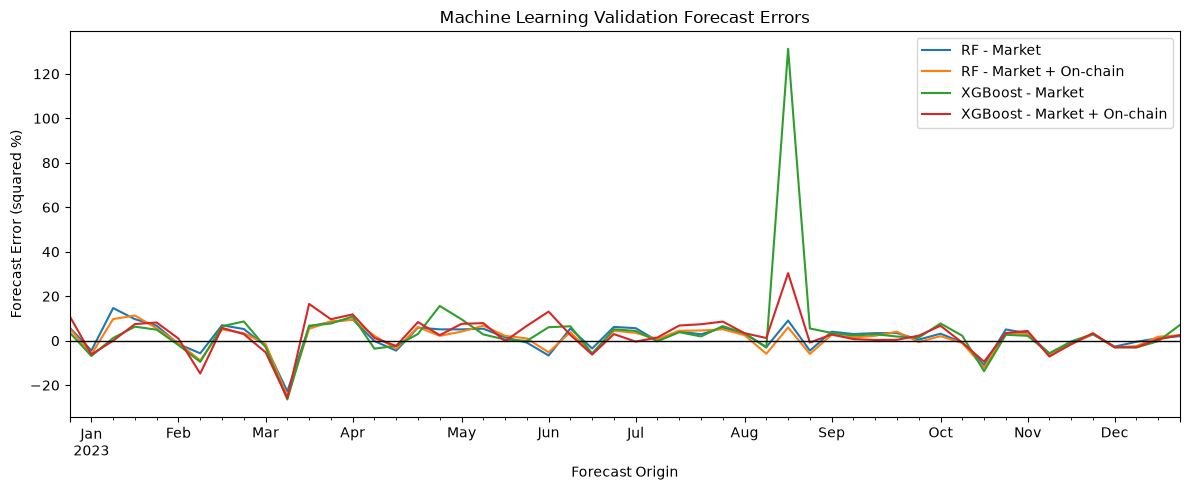

In [50]:
import matplotlib.pyplot as plt

models = [
    "RF - Market",
    "RF - Market + On-chain",
    "XGBoost - Market",
    "XGBoost - Market + On-chain"
]

# Rescale errors to squared percentage-return units
errors = pd.DataFrame(index=comparison.index)

for name in models:
    errors[name] = (
        comparison[name] - comparison["actual"]
    ) * 10000

fig, ax = plt.subplots(figsize=(12, 5))

errors.plot(ax=ax)

ax.axhline(0, color="black", linewidth=1)

ax.set_title("Machine Learning Validation Forecast Errors")
ax.set_ylabel("Forecast Error (squared %)")
ax.set_xlabel("Forecast Origin")

plt.tight_layout()
plt.show()

In [51]:
error_summary = pd.DataFrame({
    "Mean Error": errors.mean(),
    "Error Std": errors.std(),
    "Largest Absolute Error": errors.abs().max(),
    "Worst Forecast Date": errors.abs().idxmax()
})

display(error_summary)

,Mean Error,Error Std,Largest Absolute Error,Worst Forecast Date
RF - Market,1.728115,6.005623,22.775574,2023-03-11
RF - Market + On-chain,1.033038,6.108239,24.997717,2023-03-11
XGBoost - Market,4.063601,19.137365,131.226742,2023-08-19
XGBoost - Market + On-chain,2.451587,8.029316,30.377704,2023-08-19


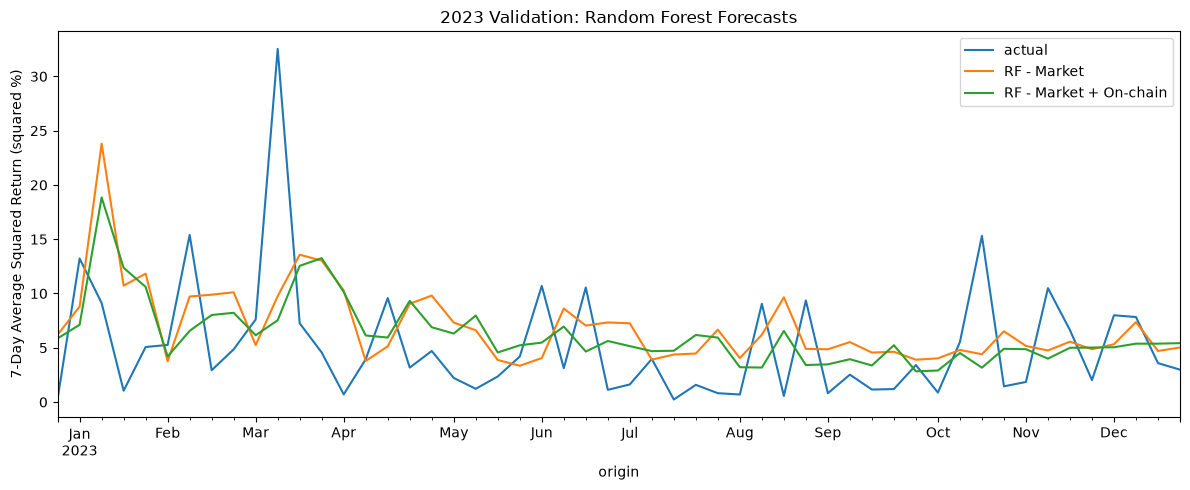

In [52]:
fig, ax = plt.subplots(figsize=(12, 5))

scale = 10000

for name in [
    "actual",
    "RF - Market",
    "RF - Market + On-chain"
]:
    (scale * comparison[name]).plot(
        ax=ax,
        label=name
    )

ax.set_title("2023 Validation: Random Forest Forecasts")
ax.set_ylabel("7-Day Average Squared Return (squared %)")
ax.legend()

plt.tight_layout()
plt.show()

In [53]:
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import make_scorer
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

H = 7

# Only use training examples whose entire target window
# falls within the original training period.
train_end = train.index.max()

training_ml = ml_data.loc[
    train.index.min():train_end - pd.Timedelta(days=H)
].copy()

training_ml = training_ml.sort_index()

# Verify that the observations are consecutive daily dates.
assert (
    training_ml.index.to_series()
    .diff()
    .dropna()
    .eq(pd.Timedelta(days=1))
    .all()
)

print("Training observations:", len(training_ml))
print("First origin:", training_ml.index.min())
print("Last origin:", training_ml.index.max())

Training observations: 1059
First origin: 2020-01-31 00:00:00
Last origin: 2022-12-24 00:00:00


In [54]:
tscv = TimeSeriesSplit(
    n_splits=4,
    test_size=91,
    gap=H
)

cv_splits = []

fold_info = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(training_ml), start=1
):

    # Weekly-spaced validation origins.
    weekly_idx = val_idx[::H]

    # Require the full 7-day target to remain
    # within this validation block.
    weekly_idx = weekly_idx[
        weekly_idx + H <= val_idx[-1]
    ]

    cv_splits.append((train_idx, weekly_idx))

    fold_info.append({
        "Fold": fold,
        "Training end": training_ml.index[train_idx[-1]],
        "Validation start": training_ml.index[weekly_idx[0]],
        "Validation end": training_ml.index[weekly_idx[-1]],
        "Weekly forecasts": len(weekly_idx)
    })

display(pd.DataFrame(fold_info))

,Fold,Training end,Validation start,Validation end,Weekly forecasts
0,1,2021-12-18,2021-12-26,2022-03-13,12
1,2,2022-03-19,2022-03-27,2022-06-12,12
2,3,2022-06-18,2022-06-26,2022-09-11,12
3,4,2022-09-17,2022-09-25,2022-12-11,12


In [55]:
def negative_mse_clipped(y_true, y_pred):

    y_pred = np.maximum(y_pred, 0.0)

    return -np.mean((y_true - y_pred)**2)


mse_scorer = make_scorer(
    negative_mse_clipped,
    greater_is_better=True
)

In [56]:
rf_base = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_grid = {
    "max_depth": [4, 5, 7],
    "min_samples_leaf": [5, 10, 20],
    "max_features": [0.8, 1.0]
}


xgb_base = XGBRegressor(
    objective="reg:squarederror",
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

xgb_grid = {
    "n_estimators": [150, 300],
    "max_depth": [2, 3],
    "learning_rate": [0.03, 0.07],
    "min_child_weight": [1, 10]
}


model_grids = {
    "RF": (rf_base, rf_grid),
    "XGBoost": (xgb_base, xgb_grid)
}

feature_sets = {
    "Market": market_features,
    "Market + On-chain": market_features + onchain_features
}

In [57]:
grid_searches = {}

grid_results = []

y_train = 10000 * training_ml["target_7"]

for model_name, (estimator, param_grid) in model_grids.items():

    for feature_name, features in feature_sets.items():

        print(f"Grid search: {model_name} - {feature_name}")

        X_train = training_ml[features]

        search = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            scoring=mse_scorer,
            cv=cv_splits,
            refit=False,
            n_jobs=1,
            verbose=0
        )

        search.fit(X_train, y_train)

        grid_searches[(model_name, feature_name)] = search

        grid_results.append({
            "Model": model_name,
            "Features": feature_name,
            "CV RMSE (x1e4)": np.sqrt(
                -search.best_score_
            ),
            "Best parameters": search.best_params_
        })

grid_summary = pd.DataFrame(grid_results)

display(grid_summary)

Grid search: RF - Market
Grid search: RF - Market + On-chain
Grid search: XGBoost - Market
Grid search: XGBoost - Market + On-chain


,Model,Features,CV RMSE (x1e4),Best parameters
0,RF,Market,14.517461,"{'max_depth': 5, 'max_features': 1.0, 'min_sam..."
1,RF,Market + On-chain,15.932578,"{'max_depth': 4, 'max_features': 0.8, 'min_sam..."
2,XGBoost,Market,15.040756,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c..."
3,XGBoost,Market + On-chain,15.266610,"{'learning_rate': 0.03, 'max_depth': 2, 'min_c..."


In [58]:
rf_full_search = grid_searches[
    ("RF", "Market + On-chain")
]

rf_cv_results = pd.DataFrame(
    rf_full_search.cv_results_
)

display(
    rf_cv_results[
        [
            "params",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").head(10)
)

,params,mean_test_score,std_test_score,rank_test_score
0,"{'max_depth': 4, 'max_features': 0.8, 'min_sam...",-253.847050,140.871869,1
1,"{'max_depth': 4, 'max_features': 0.8, 'min_sam...",-254.276348,136.261786,2
4,"{'max_depth': 4, 'max_features': 1.0, 'min_sam...",-257.303858,142.833337,3
2,"{'max_depth': 4, 'max_features': 0.8, 'min_sam...",-257.663869,126.319059,4
3,"{'max_depth': 4, 'max_features': 1.0, 'min_sam...",-262.114909,147.500514,5
5,"{'max_depth': 4, 'max_features': 1.0, 'min_sam...",-262.740248,129.018834,6
8,"{'max_depth': 5, 'max_features': 0.8, 'min_sam...",-263.340750,126.208086,7
7,"{'max_depth': 5, 'max_features': 0.8, 'min_sam...",-263.365734,139.712579,8
14,"{'max_depth': 7, 'max_features': 0.8, 'min_sam...",-264.366798,125.818360,9
11,"{'max_depth': 5, 'max_features': 1.0, 'min_sam...",-266.718818,130.578189,10


In [59]:
from sklearn.base import clone

tuned_models = {}

for (model_name, feature_name), search in grid_searches.items():

    base_model = model_grids[model_name][0]

    tuned_models[(model_name, feature_name)] = (
        clone(base_model).set_params(**search.best_params_)
    )

In [60]:
def expanding_ml_forecasts(
    estimator,
    data,
    features,
    origins,
    horizon=7
):

    predictions = []

    for origin in origins:

        # The final admissible training origin is t-H.
        cutoff = origin - pd.Timedelta(days=horizon)

        history = data.loc[
            data.index <= cutoff
        ]

        X_train = history[features]
        y_train = 10000 * history["target_7"]

        X_forecast = data.loc[[origin], features]

        fitted = clone(estimator)

        fitted.fit(X_train, y_train)

        forecast = fitted.predict(X_forecast)[0]

        # Enforce nonnegative forecasts.
        forecast = max(float(forecast), 0.0)

        predictions.append(forecast / 10000)

    return pd.Series(
        predictions,
        index=origins,
        name="forecast"
    )

In [61]:
validation_origins = validation_forecasts.index

tuned_validation = validation_forecasts[
    ["actual", "Naive", "GARCH(1,1)"]
].copy()

for (model_name, feature_name), estimator in tuned_models.items():

    name = f"{model_name} - {feature_name}"

    tuned_validation[name] = expanding_ml_forecasts(
        estimator=estimator,
        data=ml_data,
        features=feature_sets[feature_name],
        origins=validation_origins,
        horizon=H
    )

display(tuned_validation.head())

,actual,Naive,"GARCH(1,1)",RF - Market,RF - Market + On-chain,XGBoost - Market,XGBoost - Market + On-chain
origin,,,,,,,
2022-12-31,0.000029,0.000044,0.000967,0.000625,0.000634,0.000615,0.000800
2023-01-07,0.001322,0.000029,0.000876,0.000879,0.001719,0.000811,0.000786
2023-01-14,0.000912,0.001322,0.001462,0.002515,0.001416,0.001199,0.001351
2023-01-21,0.000104,0.000912,0.001447,0.001067,0.001179,0.000872,0.000905
2023-01-28,0.000507,0.000104,0.001055,0.001179,0.000979,0.000955,0.000899


In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def forecasting_scores(
    forecasts,
    actual_col="actual"
):

    actual = forecasts[actual_col]

    rows = []

    for name in forecasts.columns.drop(actual_col):

        predicted = forecasts[name]

        rows.append({
            "Model": name,
            "MAE (x1e4)": 10000 * mean_absolute_error(
                actual, predicted
            ),
            "RMSE (x1e4)": 10000 * np.sqrt(
                mean_squared_error(actual, predicted)
            )
        })

    return (
        pd.DataFrame(rows)
        .set_index("Model")
        .sort_values("RMSE (x1e4)")
    )


tuned_scores = forecasting_scores(tuned_validation)

display(tuned_scores.round(4))

,MAE (x1e4),RMSE (x1e4)
Model,,
RF - Market,4.8662,6.2487
XGBoost - Market + On-chain,5.2877,6.4532
RF - Market + On-chain,5.0949,6.5783
"GARCH(1,1)",6.4468,7.4586
Naive,5.2964,7.5500
XGBoost - Market,7.0988,18.6699


In [63]:
from itertools import combinations

ablation_sets = {}

for k in range(len(onchain_features) + 1):

    for subset in combinations(onchain_features, k):

        if len(subset) == 0:
            name = "Market only"
        else:
            name = " + ".join(subset)

        ablation_sets[name] = (
            market_features + list(subset)
        )

print("Number of ablation configurations:", len(ablation_sets))

Number of ablation configurations: 8


In [64]:
# Use the RF hyperparameters selected for all on-chain variables.
rf_ablation_model = tuned_models[
    ("RF", "Market + On-chain")
]

ablation_forecasts = validation_forecasts[
    ["actual"]
].copy()

for name, features in ablation_sets.items():

    print(f"Ablation: {name}")

    ablation_forecasts[name] = expanding_ml_forecasts(
        estimator=rf_ablation_model,
        data=ml_data,
        features=features,
        origins=validation_origins,
        horizon=H
    )

ablation_scores = forecasting_scores(
    ablation_forecasts
)

display(ablation_scores.round(4))

Ablation: Market only
Ablation: hash_rate_lag7
Ablation: difficulty_lag7
Ablation: fees_btc_lag7
Ablation: hash_rate_lag7 + difficulty_lag7
Ablation: hash_rate_lag7 + fees_btc_lag7
Ablation: difficulty_lag7 + fees_btc_lag7
Ablation: hash_rate_lag7 + difficulty_lag7 + fees_btc_lag7


,MAE (x1e4),RMSE (x1e4)
Model,,
difficulty_lag7,4.9820,6.4620
difficulty_lag7 + fees_btc_lag7,5.0087,6.4806
hash_rate_lag7 + difficulty_lag7,5.0561,6.5677
hash_rate_lag7 + difficulty_lag7 + fees_btc_lag7,5.0949,6.5783
hash_rate_lag7 + fees_btc_lag7,5.2720,6.7880
hash_rate_lag7,5.2657,6.8088
fees_btc_lag7,5.4482,6.9437
Market only,5.4657,7.0195


In [65]:
baseline_rmse = ablation_scores.loc[
    "Market only", "RMSE (x1e4)"
]

ablation_scores["RMSE improvement (%)"] = (
    100
    * (
        baseline_rmse
        - ablation_scores["RMSE (x1e4)"]
    )
    / baseline_rmse
)

display(
    ablation_scores.sort_values(
        "RMSE (x1e4)"
    ).round(4)
)

,MAE (x1e4),RMSE (x1e4),RMSE improvement (%)
Model,,,
difficulty_lag7,4.9820,6.4620,7.9430
difficulty_lag7 + fees_btc_lag7,5.0087,6.4806,7.6769
hash_rate_lag7 + difficulty_lag7,5.0561,6.5677,6.4371
hash_rate_lag7 + difficulty_lag7 + fees_btc_lag7,5.0949,6.5783,6.2858
hash_rate_lag7 + fees_btc_lag7,5.2720,6.7880,3.2986
hash_rate_lag7,5.2657,6.8088,3.0013
fees_btc_lag7,5.4482,6.9437,1.0806
Market only,5.4657,7.0195,0.0000


In [66]:
import numpy as np
import pandas as pd

H = 7

# Restrict all hyperparameter tuning to 2020–2022.
# The final seven training origins must be excluded
# because their targets are not fully observable in 2022.
training_ml = ml_data.loc[
    train.index.min():
    train.index.max() - pd.Timedelta(days=H)
].sort_index().copy()

fold_periods = [
    ("2021-04-01", "2021-06-30"),
    ("2021-10-01", "2021-12-31"),
    ("2022-04-01", "2022-06-30"),
    ("2022-10-01", "2022-12-24")
]

cv_splits = []
fold_summary = []

for fold, (start, end) in enumerate(fold_periods, start=1):

    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    # Training labels must be fully known at
    # the first forecast origin.
    cutoff = start - pd.Timedelta(days=H)

    train_idx = np.flatnonzero(
        training_ml.index <= cutoff
    )

    # Weekly forecast origins with complete targets
    # inside the validation interval.
    weekly_dates = pd.date_range(
        start=start,
        end=end - pd.Timedelta(days=H),
        freq="7D"
    )

    val_idx = training_ml.index.get_indexer(weekly_dates)

    assert len(train_idx) > 0
    assert (val_idx >= 0).all()
    assert train_idx[-1] < val_idx[0]

    cv_splits.append((train_idx, val_idx))

    fold_summary.append({
        "Fold": fold,
        "Train start": training_ml.index[train_idx[0]],
        "Train end": training_ml.index[train_idx[-1]],
        "Validation start": training_ml.index[val_idx[0]],
        "Validation end": training_ml.index[val_idx[-1]],
        "Training samples": len(train_idx),
        "Weekly forecasts": len(val_idx)
    })

display(pd.DataFrame(fold_summary))

,Fold,Train start,Train end,Validation start,Validation end,Training samples,Weekly forecasts
0,1,2020-01-31,2021-03-25,2021-04-01,2021-06-17,420,12
1,2,2020-01-31,2021-09-24,2021-10-01,2021-12-24,603,13
2,3,2020-01-31,2022-03-25,2022-04-01,2022-06-17,785,12
3,4,2020-01-31,2022-09-24,2022-10-01,2022-12-17,968,12


In [67]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import make_scorer
from sklearn.base import clone
from xgboost import XGBRegressor

rf_base = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_search_space = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_leaf": [5, 10, 20, 40],
    "max_features": [0.6, 0.8, 1.0]
}

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

xgb_search_space = {
    "n_estimators": [100, 200, 400],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.02, 0.04, 0.08, 0.12],
    "min_child_weight": [1, 5, 10, 20],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "reg_lambda": [0.3, 1.0, 3.0, 10.0]
}

In [68]:
search_specs = {
    "RF - Market": (
        rf_base,
        rf_search_space,
        market_features
    ),

    "RF - Market + Difficulty": (
        rf_base,
        rf_search_space,
        market_features + ["difficulty_lag7"]
    ),

    "RF - Market + On-chain": (
        rf_base,
        rf_search_space,
        market_features + onchain_features
    ),

    "XGBoost - Market": (
        xgb_base,
        xgb_search_space,
        market_features
    ),

    "XGBoost - Market + On-chain": (
        xgb_base,
        xgb_search_space,
        market_features + onchain_features
    )
}

In [69]:
def negative_mse_clipped(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0.0)
    return -np.mean((y_true - y_pred)**2)

mse_scorer = make_scorer(
    negative_mse_clipped,
    greater_is_better=True
)

final_searches = {}
final_estimators = {}
rows = []

y_cv = 10000 * training_ml["target_7"]

for name, (base, space, features) in search_specs.items():

    print(f"Searching: {name}")

    search = RandomizedSearchCV(
        estimator=base,
        param_distributions=space,
        n_iter=24,
        scoring=mse_scorer,
        cv=cv_splits,
        random_state=546,
        n_jobs=1,
        refit=False,
        verbose=0,
        error_score="raise"
    )

    search.fit(training_ml[features], y_cv)

    final_searches[name] = search

    final_estimators[name] = (
        clone(base).set_params(**search.best_params_)
    )

    rows.append({
        "Model": name,
        "CV RMSE (x1e4)": np.sqrt(-search.best_score_),
        **search.best_params_
    })

final_search_summary = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values("CV RMSE (x1e4)")
)

display(final_search_summary)

Searching: RF - Market
Searching: RF - Market + Difficulty
Searching: RF - Market + On-chain
Searching: XGBoost - Market
Searching: XGBoost - Market + On-chain


,CV RMSE (x1e4),min_samples_leaf,max_features,max_depth,subsample,reg_lambda,n_estimators,min_child_weight,learning_rate,colsample_bytree
Model,,,,,,,,,,
RF - Market + Difficulty,14.150029,10.0,0.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RF - Market,14.738300,20.0,0.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost - Market + On-chain,14.939657,NaN,NaN,2.0,0.7,10.0,100.0,1.0,0.02,0.7
RF - Market + On-chain,15.153545,10.0,0.8,3.0,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost - Market,15.565879,NaN,NaN,2.0,0.7,10.0,100.0,1.0,0.02,0.7


In [70]:
fold_rows = []

for name, search in final_searches.items():

    best_idx = search.best_index_

    row = {"Model": name}

    for i in range(len(cv_splits)):

        neg_mse = search.cv_results_[
            f"split{i}_test_score"
        ][best_idx]

        row[f"Fold {i+1} RMSE"] = np.sqrt(-neg_mse)

    fold_rows.append(row)

fold_performance = (
    pd.DataFrame(fold_rows)
    .set_index("Model")
)

display(fold_performance.round(4))

,Fold 1 RMSE,Fold 2 RMSE,Fold 3 RMSE,Fold 4 RMSE
Model,,,,
RF - Market,13.6672,11.1242,17.5509,15.8207
RF - Market + Difficulty,10.8883,7.4734,16.6410,18.6967
RF - Market + On-chain,11.1490,11.7889,16.9982,19.1391
XGBoost - Market,15.7705,11.2162,17.1511,17.3354
XGBoost - Market + On-chain,13.1787,10.0084,16.8431,18.3095


In [71]:
final_validation = validation_forecasts[
    ["actual", "Naive", "GARCH(1,1)"]
].copy()

for name, estimator in final_estimators.items():

    features = search_specs[name][2]

    final_validation[name] = expanding_ml_forecasts(
        estimator=estimator,
        data=ml_data,
        features=features,
        origins=validation_forecasts.index,
        horizon=7
    )

final_validation_scores = forecasting_scores(
    final_validation
)

display(final_validation_scores.round(4))

,MAE (x1e4),RMSE (x1e4)
Model,,
RF - Market + On-chain,4.7446,5.8931
RF - Market + Difficulty,4.6289,6.0023
RF - Market,4.8724,6.1426
XGBoost - Market + On-chain,5.4373,6.4551
"GARCH(1,1)",6.4468,7.4586
XGBoost - Market,6.0173,7.4689
Naive,5.2964,7.5500


In [72]:
frozen_names = [
    "RF - Market",
    "RF - Market + Difficulty",
    "RF - Market + On-chain",
    "XGBoost - Market",
    "XGBoost - Market + On-chain"
]

frozen_models = {
    name: final_estimators[name]
    for name in frozen_names
}

frozen_features = {
    name: list(search_specs[name][2])
    for name in frozen_names
}

# Record selected specifications
for name in frozen_names:
    print(f"\n{name}")
    print("Features:", frozen_features[name])
    print("Parameters:", frozen_models[name].get_params())


RF - Market
Features: ['r_t', 'abs_r_t', 'v_t', 'rv_7', 'rv_14', 'rv_30', 'return_7', 'range_t', 'log_volume', 'volume_change_7']
Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.8, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 20, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

RF - Market + Difficulty
Features: ['r_t', 'abs_r_t', 'v_t', 'rv_7', 'rv_14', 'rv_30', 'return_7', 'range_t', 'log_volume', 'volume_change_7', 'difficulty_lag7']
Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 0.6, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 10, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None

In [73]:
# Reuse the 52 weekly test origins from GARCH evaluation
test_origins = test_forecasts.index

final_ml_test = test_forecasts[
    ["actual", "Naive", "GARCH(1,1)"]
].copy()

for name in frozen_names:

    print(f"Evaluating: {name}")

    final_ml_test[name] = expanding_ml_forecasts(
        estimator=frozen_models[name],
        data=ml_data,
        features=frozen_features[name],
        origins=test_origins,
        horizon=7
    )

# Verify the same targets are used
assert len(final_ml_test) == 52

assert np.allclose(
    final_ml_test["actual"],
    ml_data.loc[test_origins, "target_7"]
)

final_ml_scores = forecasting_scores(final_ml_test)

display(final_ml_scores.round(4))

Evaluating: RF - Market
Evaluating: RF - Market + Difficulty
Evaluating: RF - Market + On-chain
Evaluating: XGBoost - Market
Evaluating: XGBoost - Market + On-chain


,MAE (x1e4),RMSE (x1e4)
Model,,
XGBoost - Market + On-chain,4.9813,6.3872
RF - Market + On-chain,4.7061,6.4265
RF - Market + Difficulty,5.1620,6.7452
XGBoost - Market,5.5739,6.8757
"GARCH(1,1)",5.5081,7.1014
RF - Market,6.2471,8.4211
Naive,5.9050,8.5961


In [74]:
naive_rmse = final_ml_scores.loc[
    "Naive", "RMSE (x1e4)"
]

final_ml_scores["RMSE improvement (%)"] = (
    100 * (
        naive_rmse - final_ml_scores["RMSE (x1e4)"]
    ) / naive_rmse
)

display(final_ml_scores.round(4))

,MAE (x1e4),RMSE (x1e4),RMSE improvement (%)
Model,,,
XGBoost - Market + On-chain,4.9813,6.3872,25.6974
RF - Market + On-chain,4.7061,6.4265,25.2401
RF - Market + Difficulty,5.1620,6.7452,21.5325
XGBoost - Market,5.5739,6.8757,20.0141
"GARCH(1,1)",5.5081,7.1014,17.3885
RF - Market,6.2471,8.4211,2.0365
Naive,5.9050,8.5961,0.0000


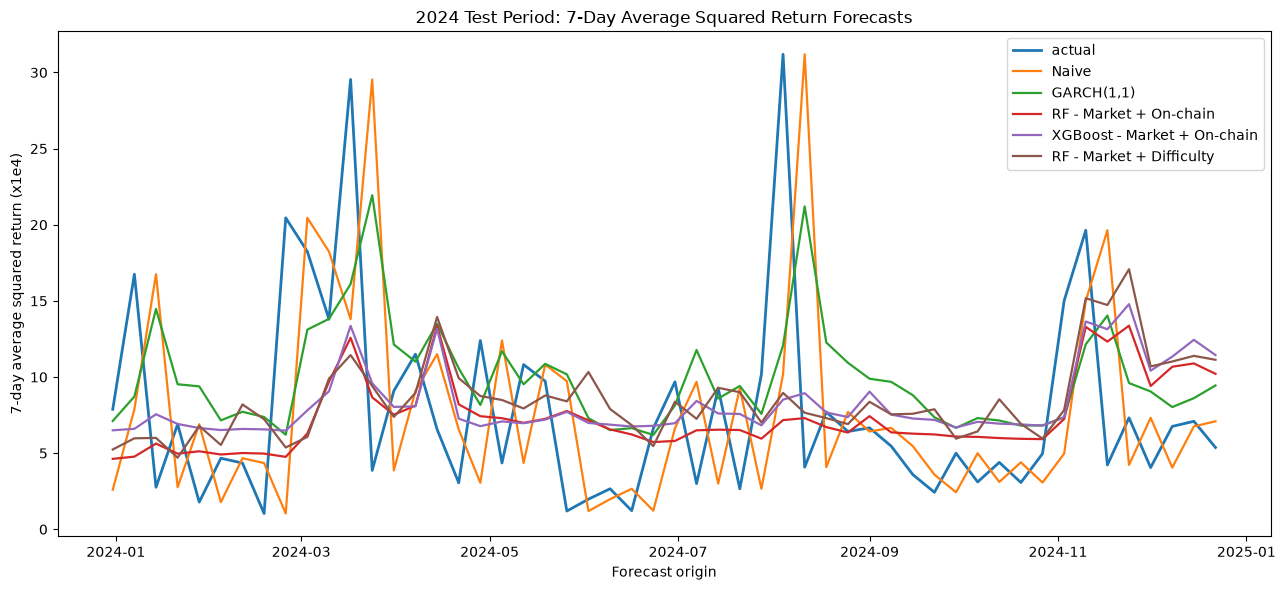

In [75]:
import matplotlib.pyplot as plt

scale = 10000  # show squared-percentage-return units

plot_cols = [
    "actual",
    "Naive",
    "GARCH(1,1)",
    "RF - Market + On-chain",
    "XGBoost - Market + On-chain",
    "RF - Market + Difficulty"
]

fig, ax = plt.subplots(figsize=(13, 6))

for col in plot_cols:
    ax.plot(
        final_ml_test.index,
        scale * final_ml_test[col],
        label=col,
        linewidth=2 if col == "actual" else 1.6
    )

ax.set_title("2024 Test Period: 7-Day Average Squared Return Forecasts")
ax.set_ylabel("7-day average squared return (x1e4)")
ax.set_xlabel("Forecast origin")
ax.legend()
plt.tight_layout()
plt.show()

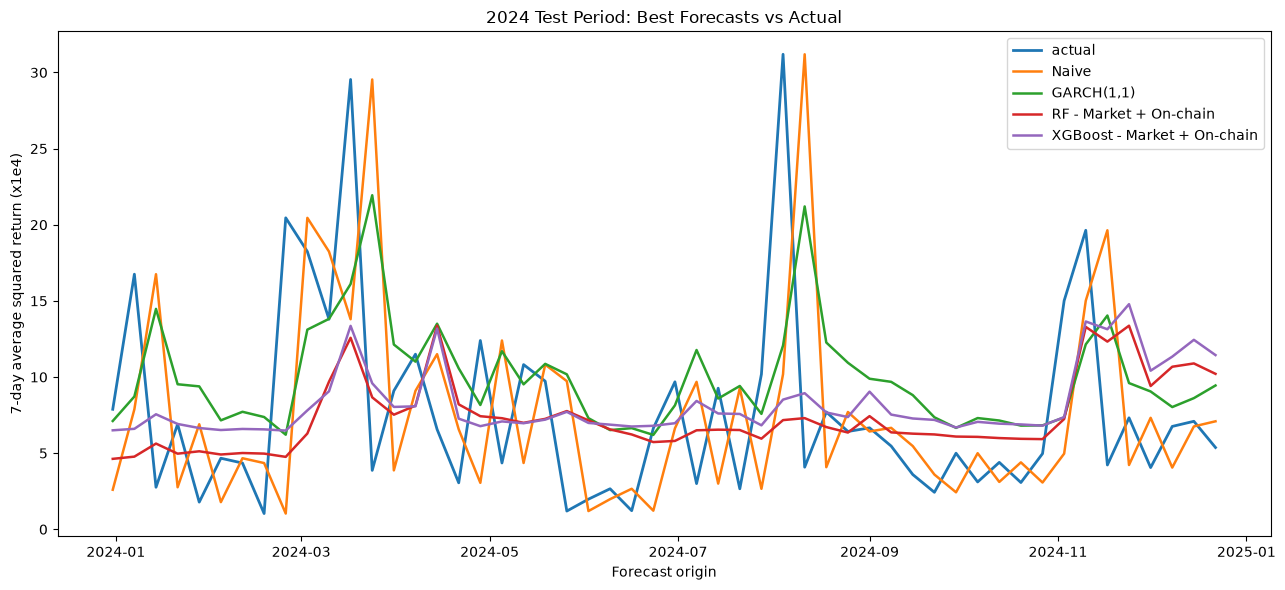

In [76]:
scale = 10000

best_plot_cols = [
    "actual",
    "Naive",
    "GARCH(1,1)",
    "RF - Market + On-chain",
    "XGBoost - Market + On-chain"
]

fig, ax = plt.subplots(figsize=(13, 6))

for col in best_plot_cols:
    ax.plot(
        final_ml_test.index,
        scale * final_ml_test[col],
        label=col,
        linewidth=2 if col == "actual" else 1.8
    )

ax.set_title("2024 Test Period: Best Forecasts vs Actual")
ax.set_ylabel("7-day average squared return (x1e4)")
ax.set_xlabel("Forecast origin")
ax.legend()
plt.tight_layout()
plt.show()

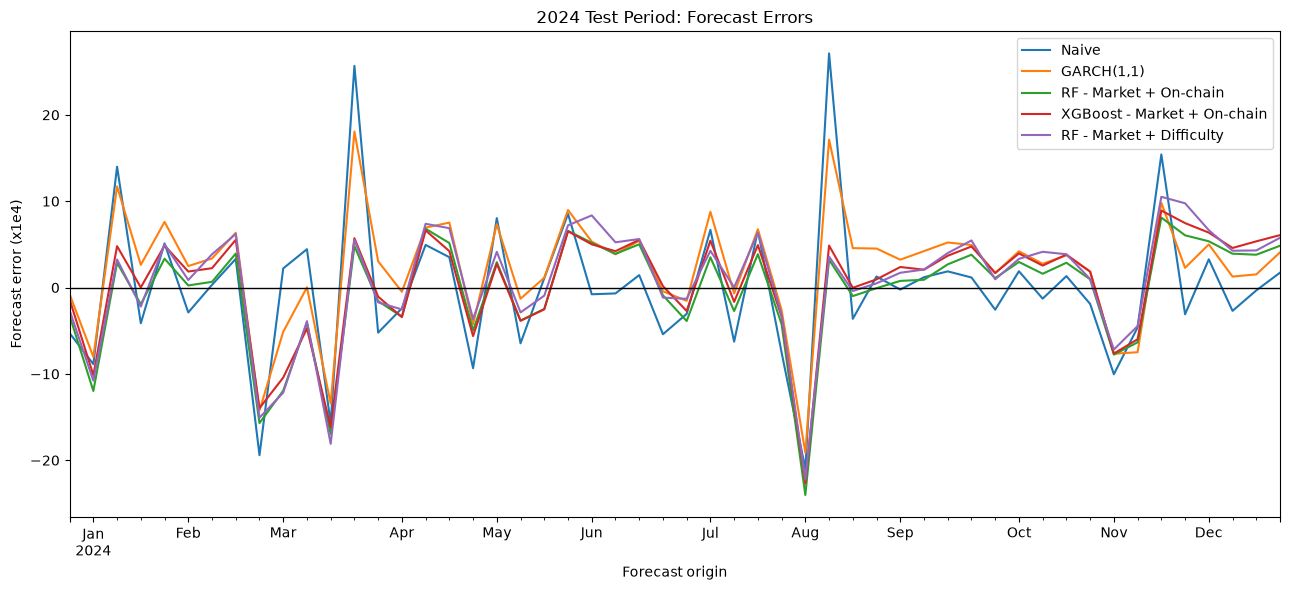

In [77]:
error_cols = [
    "Naive",
    "GARCH(1,1)",
    "RF - Market + On-chain",
    "XGBoost - Market + On-chain",
    "RF - Market + Difficulty"
]

errors_test = pd.DataFrame(index=final_ml_test.index)

for col in error_cols:
    errors_test[col] = 10000 * (final_ml_test[col] - final_ml_test["actual"])

fig, ax = plt.subplots(figsize=(13, 6))

errors_test.plot(ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("2024 Test Period: Forecast Errors")
ax.set_ylabel("Forecast error (x1e4)")
ax.set_xlabel("Forecast origin")
plt.tight_layout()
plt.show()

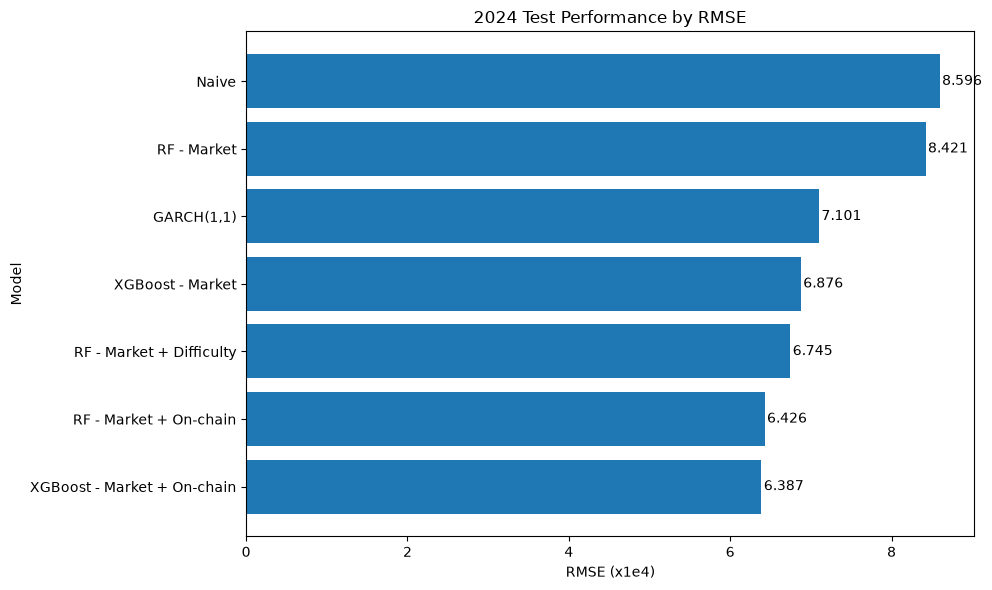

In [78]:
scores_plot = final_ml_scores.copy().sort_values("RMSE (x1e4)")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(scores_plot.index, scores_plot["RMSE (x1e4)"])
ax.set_title("2024 Test Performance by RMSE")
ax.set_xlabel("RMSE (x1e4)")
ax.set_ylabel("Model")

for i, value in enumerate(scores_plot["RMSE (x1e4)"]):
    ax.text(value + 0.03, i, f"{value:.3f}", va="center")

plt.tight_layout()
plt.show()

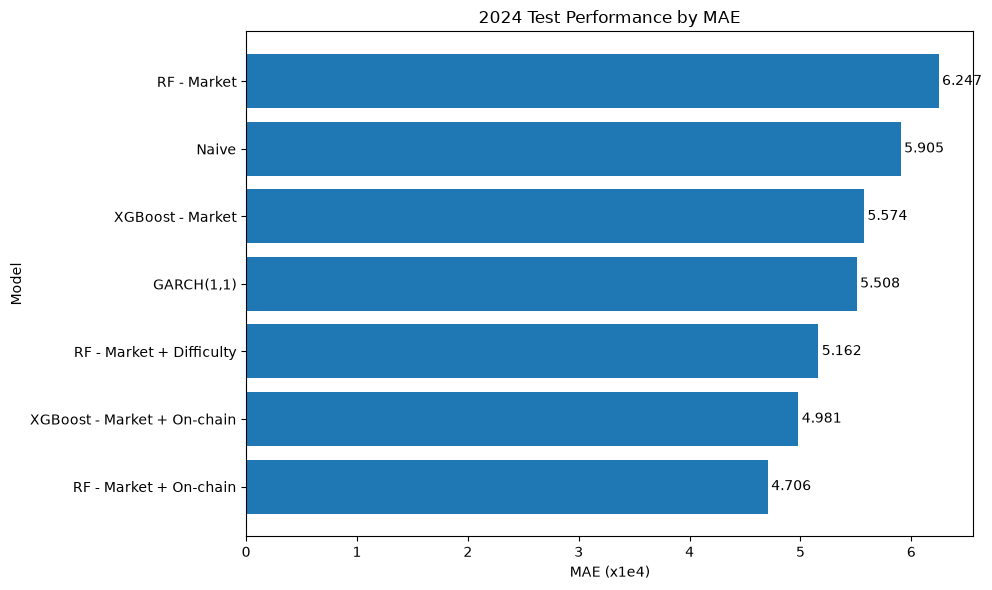

In [79]:
scores_plot = final_ml_scores.copy().sort_values("MAE (x1e4)")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(scores_plot.index, scores_plot["MAE (x1e4)"])
ax.set_title("2024 Test Performance by MAE")
ax.set_xlabel("MAE (x1e4)")
ax.set_ylabel("Model")

for i, value in enumerate(scores_plot["MAE (x1e4)"]):
    ax.text(value + 0.03, i, f"{value:.3f}", va="center")

plt.tight_layout()
plt.show()

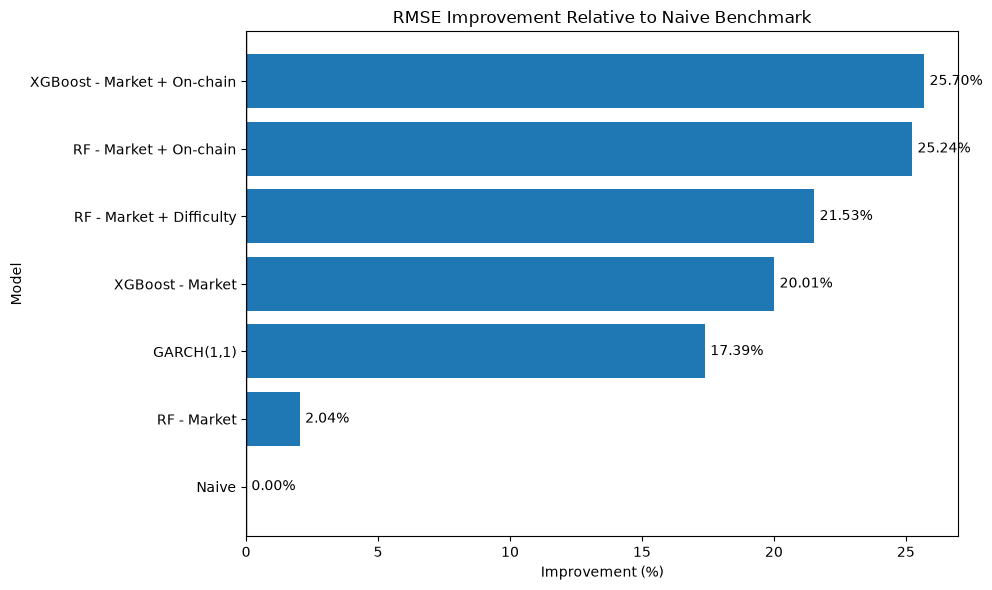

In [80]:
improvement_plot = final_ml_scores.copy().sort_values("RMSE improvement (%)", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(improvement_plot.index, improvement_plot["RMSE improvement (%)"])
ax.axvline(0, color="black", linewidth=1)
ax.set_title("RMSE Improvement Relative to Naive Benchmark")
ax.set_xlabel("Improvement (%)")
ax.set_ylabel("Model")

for i, value in enumerate(improvement_plot["RMSE improvement (%)"]):
    ax.text(value + 0.2, i, f"{value:.2f}%", va="center")

plt.tight_layout()
plt.show()

In [81]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

def dm_hac(
    forecasts,
    model_a,
    model_b,
    loss="squared",
    hac_lags=3,
    scale=10000
):
    """
    Diebold-Mariano style test using HAC standard errors.
    
    H0: E[d_t] = 0, where d_t = L_a,t - L_b,t
    Negative mean difference favors model_a.
    """

    data = forecasts[["actual", model_a, model_b]].dropna().copy()

    y = scale * data["actual"].to_numpy()
    fa = scale * data[model_a].to_numpy()
    fb = scale * data[model_b].to_numpy()

    ea = y - fa
    eb = y - fb

    if loss == "squared":
        d = ea**2 - eb**2
    elif loss == "absolute":
        d = np.abs(ea) - np.abs(eb)
    else:
        raise ValueError("loss must be 'squared' or 'absolute'")

    X = np.ones((len(d), 1))

    res = sm.OLS(d, X).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": hac_lags, "use_correction": True},
        use_t=True
    )

    t_stat = float(res.tvalues[0])
    p_two_sided = float(res.pvalues[0])

    # one-sided p-value for H1: model_a better than model_b
    # i.e. E[d_t] < 0
    df = int(res.df_resid)
    p_one_sided_less = stats.t.cdf(t_stat, df=df)

    return pd.Series({
        "N": len(d),
        "Mean loss difference": float(res.params[0]),
        "Standard error": float(res.bse[0]),
        "DM-HAC statistic": t_stat,
        "p-value (two-sided)": p_two_sided,
        "p-value (one-sided, model_a better)": p_one_sided_less
    })

In [82]:
dm_comparisons = [
    ("XGBoost - Market + On-chain", "Naive"),
    ("XGBoost - Market + On-chain", "GARCH(1,1)"),
    ("RF - Market + On-chain", "Naive"),
    ("RF - Market + On-chain", "GARCH(1,1)"),
    ("XGBoost - Market + On-chain", "RF - Market + On-chain"),
    ("XGBoost - Market + On-chain", "XGBoost - Market"),
    ("RF - Market + On-chain", "RF - Market"),
    ("RF - Market + Difficulty", "RF - Market")
]

dm_rows = []

for model_a, model_b in dm_comparisons:
    out = dm_hac(
        final_ml_test,
        model_a=model_a,
        model_b=model_b,
        loss="squared",
        hac_lags=3
    )
    row = {"Model A": model_a, "Model B": model_b}
    row.update(out.to_dict())
    dm_rows.append(row)

dm_results = pd.DataFrame(dm_rows)

display(dm_results.round(4))

,Model A,Model B,N,Mean loss difference,Standard error,DM-HAC statistic,p-value (two-sided),"p-value (one-sided, model_a better)"
0,XGBoost - Market + On-chain,Naive,52.0,-33.0979,16.2734,-2.0339,0.0472,0.0236
1,XGBoost - Market + On-chain,"GARCH(1,1)",52.0,-9.6341,6.5263,-1.4762,0.1460,0.0730
2,RF - Market + On-chain,Naive,52.0,-32.5942,15.5397,-2.0975,0.0409,0.0205
3,RF - Market + On-chain,"GARCH(1,1)",52.0,-9.1304,6.9794,-1.3082,0.1967,0.0983
4,XGBoost - Market + On-chain,RF - Market + On-chain,52.0,-0.5037,2.3488,-0.2145,0.8310,0.4155
5,XGBoost - Market + On-chain,XGBoost - Market,52.0,-6.4795,7.9523,-0.8148,0.4190,0.2095
6,RF - Market + On-chain,RF - Market,52.0,-29.6152,22.7049,-1.3044,0.1980,0.0990
7,RF - Market + Difficulty,RF - Market,52.0,-25.4172,21.1974,-1.1991,0.2360,0.1180


In [83]:
dm_rows_abs = []

for model_a, model_b in dm_comparisons:
    out = dm_hac(
        final_ml_test,
        model_a=model_a,
        model_b=model_b,
        loss="absolute",
        hac_lags=3
    )
    row = {"Model A": model_a, "Model B": model_b}
    row.update(out.to_dict())
    dm_rows_abs.append(row)

dm_results_abs = pd.DataFrame(dm_rows_abs)

display(dm_results_abs.round(4))

,Model A,Model B,N,Mean loss difference,Standard error,DM-HAC statistic,p-value (two-sided),"p-value (one-sided, model_a better)"
0,XGBoost - Market + On-chain,Naive,52.0,-0.9237,0.7769,-1.1889,0.2400,0.1200
1,XGBoost - Market + On-chain,"GARCH(1,1)",52.0,-0.5268,0.4895,-1.0762,0.2869,0.1435
2,RF - Market + On-chain,Naive,52.0,-1.1989,0.7185,-1.6685,0.1013,0.0507
3,RF - Market + On-chain,"GARCH(1,1)",52.0,-0.8020,0.5111,-1.5691,0.1228,0.0614
4,XGBoost - Market + On-chain,RF - Market + On-chain,52.0,0.2752,0.1653,1.6651,0.1020,0.9490
5,XGBoost - Market + On-chain,XGBoost - Market,52.0,-0.5926,0.4221,-1.4041,0.1664,0.0832
6,RF - Market + On-chain,RF - Market,52.0,-1.5410,0.9553,-1.6130,0.1129,0.0565
7,RF - Market + Difficulty,RF - Market,52.0,-1.0851,0.8881,-1.2218,0.2274,0.1137


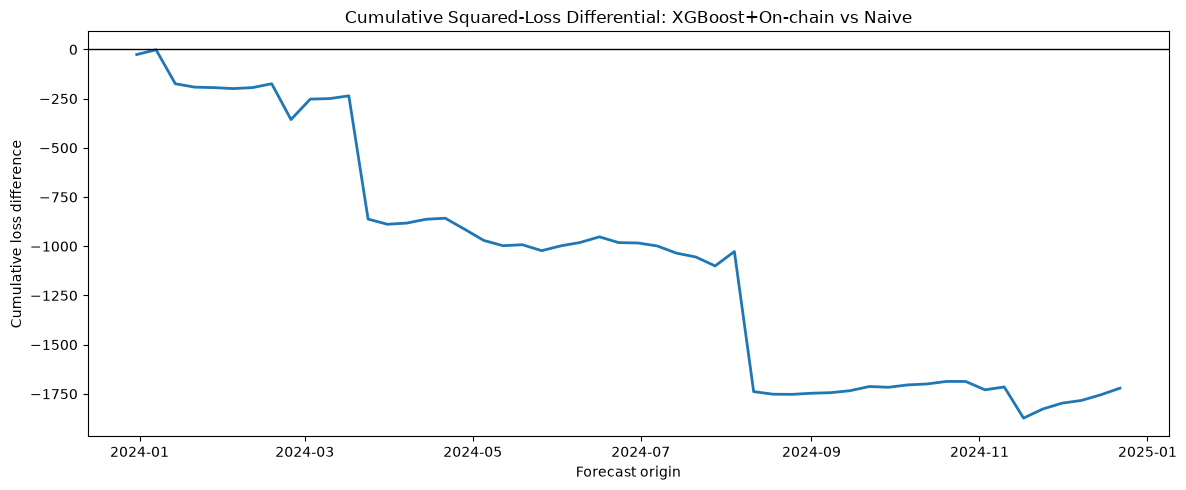

In [84]:
scale = 10000

y = scale * final_ml_test["actual"]
f_a = scale * final_ml_test["XGBoost - Market + On-chain"]
f_b = scale * final_ml_test["Naive"]

d = (y - f_a)**2 - (y - f_b)**2

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(final_ml_test.index, d.cumsum(), linewidth=2)
ax.axhline(0, color="black", linewidth=1)

ax.set_title("Cumulative Squared-Loss Differential: XGBoost+On-chain vs Naive")
ax.set_ylabel("Cumulative loss difference")
ax.set_xlabel("Forecast origin")

plt.tight_layout()
plt.show()